# Superstore Sales Analysis — Business Questions

**Notebook 4 of 4**

This notebook applies the cleaned dataset and the patterns identified during
exploratory analysis (Notebook 3) to answer 39 targeted business questions,
organized into seven categories:

- Overall Business Performance
- Regional Performance
- Product & Category Analysis
- Customer Analysis
- Discount & Profitability
- Shipping & Operations
- Time Series & Trends

**Objective:** Translate the dataset into concrete, decision-ready answers —
each question is addressed with a calculation or visualization, followed by
a brief interpretation connecting the result to the business.

**Dataset:** 8,399 orders × 33 columns | Period: January 2009 – December 2012

## 1️ Setup & Data Loading


In [1]:
from google.colab import drive
drive.mount("/content/drive")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

df = pd.read_csv("/content/drive/MyDrive/Superstore-Analysis/superstore_cleaned.csv")
df["order_date"] = pd.to_datetime(df["order_date"])
df["ship_date"] = pd.to_datetime(df["ship_date"])

discount_order = ["No Discount", "Low", "Medium", "High"]
sales_order = ["Small", "Medium", "Large", "Very Large"]
df["discount_band"] = pd.Categorical(df["discount_band"], categories=discount_order, ordered=True)
df["sales_band"] = pd.Categorical(df["sales_band"], categories=sales_order, ordered=True)

def fmt_currency(value):
    """Format a number as a currency string, e.g. 1234567.8 -> '$1,234,567.80'."""
    return f"${value:,.2f}"

print(f"Dataset loaded: {df.shape[0]:,} rows x {df.shape[1]} columns")

Mounted at /content/drive
Dataset loaded: 8,399 rows x 33 columns


## Business Questions Analysis

With the dataset understood, cleaned, and explored, this section moves into
answering the 39 business questions defined for this project. Each question
follows a consistent structure:

- **Question** — the business question being answered
- **Analysis** — the code used to derive the answer, including a chart where relevant
- **Insight** — a short interpretation connecting the result back to the business

The questions are organized into seven categories:

1. Overall Business Performance
2. Regional Performance
3. Product & Category Analysis
4. Customer Analysis
5. Discount & Profitability
6. Shipping & Operations
7. Time Series & Trends

---

## Category 1: Overall Business Performance

**Business Question:** "Give me a snapshot of how the business is doing overall."

This section establishes the top-line numbers — revenue, profit, order volume,
and growth trend — that later categories will build on.

### **Q1.** What is the total revenue, total profit, total number of orders, and total quantity sold across all years?

In [2]:
total_revenue = df["sales"].sum()
total_profit = df["profit"].sum()
total_orders = df["order_id"].nunique()
total_quantity = df["order_quantity"].sum()

print(f"Total Revenue   : {fmt_currency(total_revenue)}")
print(f"Total Profit    : {fmt_currency(total_profit)}")
print(f"Total Orders    : {total_orders:,}")
print(f"Total Quantity  : {total_quantity:,} units")

Total Revenue   : $14,915,600.82
Total Profit    : $1,521,767.96
Total Orders    : 5,496
Total Quantity  : 214,777 units


**Insight:**
- Across 2009-2012, the business processed **5,496 orders**, moving
  **214,777 units**, and generating **\$14,915,600.82** in total revenue.
- Of that revenue, **\$1,521,767.96** converted to profit — this raw figure
  sets the baseline; Q2 will express it as a margin percentage to judge how
  efficient that conversion actually is.

### Q2. What is the overall profit margin of the business? (Profit / Sales × 100)

In [3]:
overall_margin = (total_profit / total_revenue) * 100
print(f"Overall Profit Margin: {overall_margin:.2f}%")

Overall Profit Margin: 10.20%


**Insight:**
- The business converts **10.20%** of every dollar in sales into profit — a
  modest but positive overall margin.
- This number is worth reading alongside a Notebook 3 finding: just over half
  of individual **orders** are unprofitable. The fact that the overall margin
  still lands at a healthy 10.20% shows the profitable orders are large or
  frequent enough to outweigh the losses — but it also means there's real
  room to improve margin further if the loss-making half can be addressed.

### Q3. How has total revenue trended month by month across all years? Is the business growing?

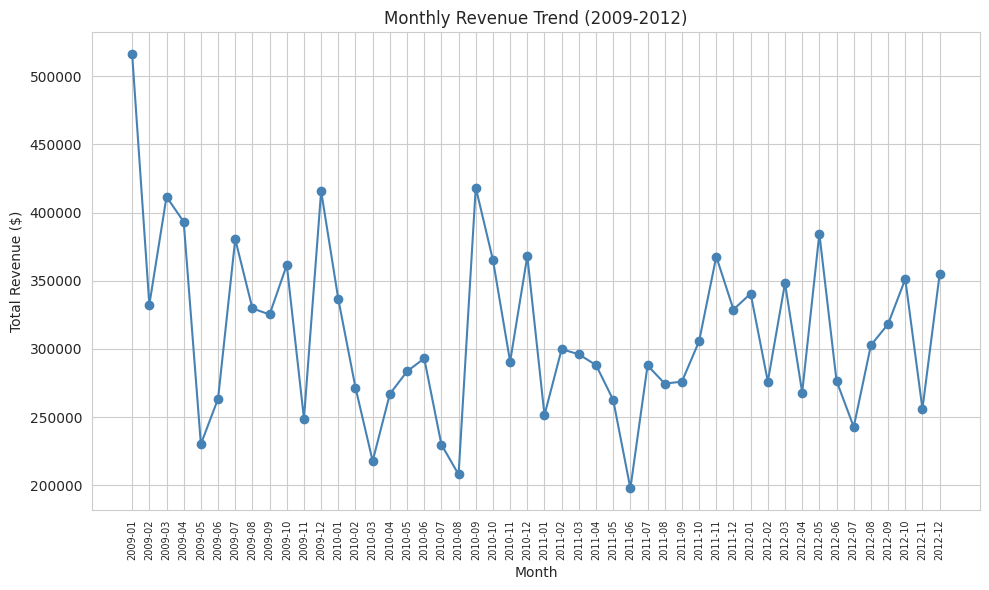

In [4]:
monthly_revenue = df.groupby(df["order_date"].dt.to_period("M"))["sales"].sum()
monthly_revenue.index = monthly_revenue.index.astype(str)

plt.plot(monthly_revenue.index, monthly_revenue.values, marker="o", linewidth=1.5, color="steelblue")
plt.title("Monthly Revenue Trend (2009-2012)")
plt.xlabel("Month")
plt.ylabel("Total Revenue ($)")
plt.xticks(rotation=90, fontsize=7)
plt.tight_layout()
plt.show()

**Insight:**
- Revenue does **not** show a clear upward growth trend over the four years —
  instead, it oscillates in a fairly consistent band, mostly between
  **\$250,000 and \$400,000** per month, with recurring sharp dips and peaks.
- January 2009 stands out as the single highest month (~\$518,000), notably
  above every other month in the dataset — worth flagging as an early outlier
  rather than the start of a trend.
- The month-to-month volatility (sharp up-down swings almost every period) is
  more prominent than any long-term trajectory — this suggests revenue is
  driven more by order-level or seasonal timing than by steady business growth.
- Takeaway: on raw monthly totals, this business looks **stable rather than
  growing** — a useful, honest finding that later quarterly/yearly aggregation
  (Q35-Q39) can help confirm or refine.

### Q4. Which year was the most profitable and which was the worst?

In [5]:
yearly_profit = df.groupby("year")["profit"].sum().sort_values(ascending=False)
print(yearly_profit.apply(fmt_currency))

year
2009    $434,538.79
2011    $381,455.99
2010    $363,871.38
2012    $341,901.81
Name: profit, dtype: object


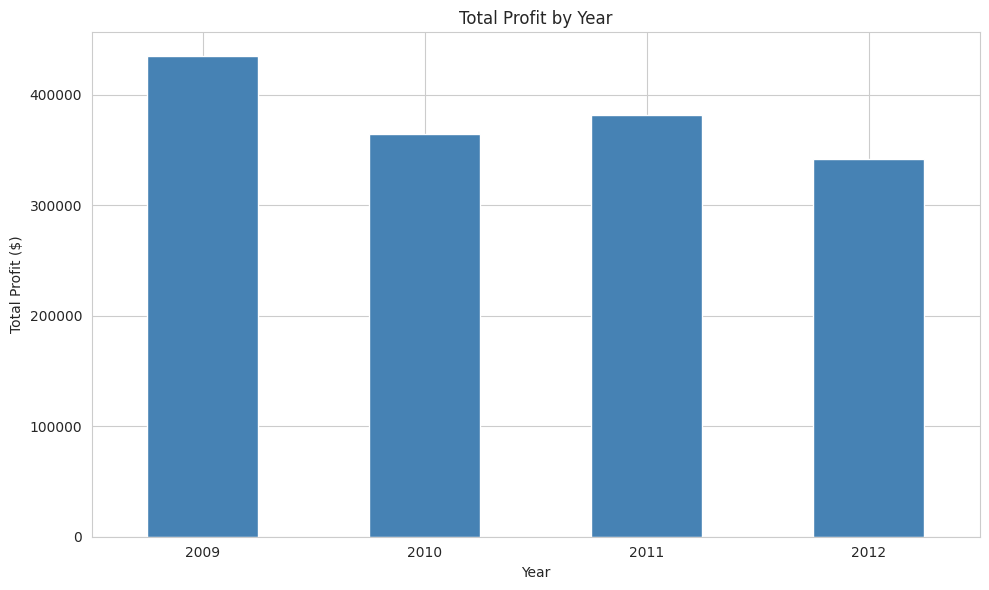

In [6]:
yearly_profit.sort_index().plot(kind="bar", color="steelblue")
plt.title("Total Profit by Year")
plt.xlabel("Year")
plt.ylabel("Total Profit ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Insight:**
- **2009** was the most profitable year (**\$434,538.79**), and **2012** was
  the weakest (**\$341,901.81**) — a **21.3% decline** in profit from the
  best year to the worst.
- Profit does not decline steadily; it dropped sharply after 2009, recovered
  somewhat in 2011, then fell again in 2012 — inconsistent with the flat/stable
  revenue pattern seen in Q3, suggesting **costs or discounting may be eating
  into profit** even in years where revenue held steady.
- This reinforces the Q3 takeaway: the business isn't in decline on the
  revenue side, but profit is trending in a less stable direction — a signal
  worth investigating further in the Discount & Profitability category later
  in this notebook.

### Q5. What is the average order value?

In [7]:
order_value = df.groupby("order_id")["sales"].sum()
average_order_value = order_value.mean()

print(f"Average Order Value: {fmt_currency(average_order_value)}")

Average Order Value: $2,713.90


**Insight:**
- The average order is worth **\$2,713.90** — a relatively high ticket size,
  consistent with a business selling furniture, technology, and bulk office
  supplies rather than small individual items.
- This figure is useful as a benchmark for later questions — e.g. when
  identifying "high revenue but negative profit" customers or products
  (Q17, Q24), \$2,713.90 is the reference point for what counts as an
  above- or below-average order.

**Category 1 Summary:**
The business generated **\$14.92M** in revenue and **\$1.52M** in profit across
2009-2012, holding a **10.20%** overall margin. Revenue shows no clear growth
trend — it oscillates within a stable band rather than climbing — while profit
has trended downward since a strong 2009, pointing to margin pressure rather
than a demand problem. Average order value sits at **\$2,713.90**, reflecting
high-ticket product lines. These baseline figures set the frame for the
regional, product, and customer breakdowns that follow.

## Category 2: Regional Performance

**Business Question:** "We want to know which parts of the country are
making us money and which are costing us."

This section breaks performance down by region, state, and city to identify
where the business is strong and where it may be losing money geographically.

### Q6. Which region generates the highest total revenue?

In [8]:
region_revenue = df.groupby("region")["sales"].sum().sort_values(ascending=False)
print(region_revenue.apply(fmt_currency))

region
Central    $4,699,167.25
West       $3,649,747.75
East       $3,416,466.47
South      $3,150,219.36
Name: sales, dtype: object


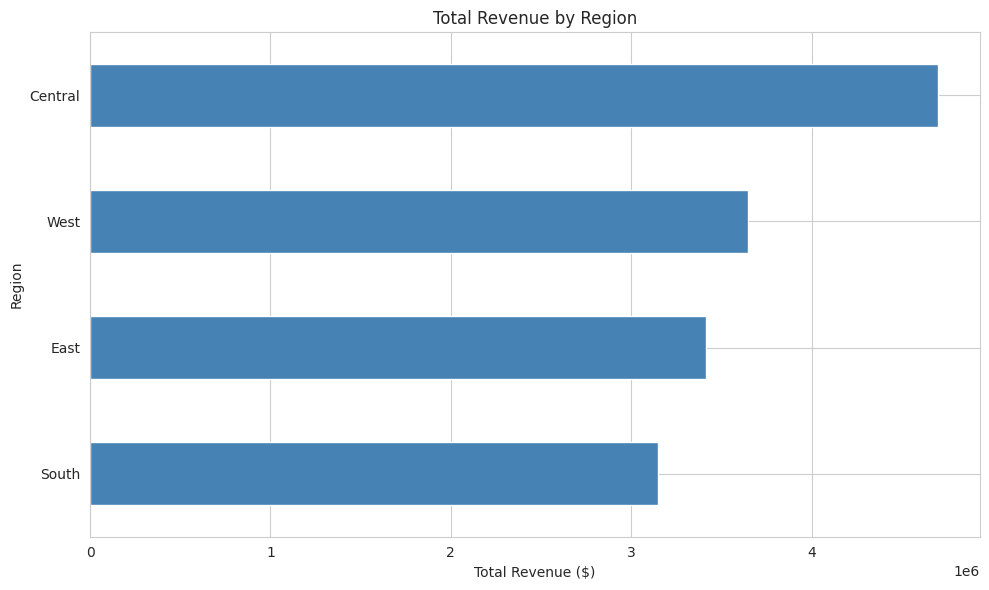

In [9]:
region_revenue.sort_values().plot(kind="barh", color="steelblue")
plt.title("Total Revenue by Region")
plt.xlabel("Total Revenue ($)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

**Insight:**
- **Central** is the clear revenue leader at **\$4.70M**, well ahead of
  **West** (**\$3.65M**), **East** (**\$3.42M**), and **South** (**\$3.15M**).
- Central generates roughly **49% more revenue than South**, the lowest
  region — a meaningful gap worth checking against profit next, since high
  revenue doesn't guarantee high profit (Notebook 3 already showed all four
  regions cluster near 47-50% profitable orders, regardless of revenue size).

### Q7. Which region generates the highest total profit?

In [10]:
region_profit = df.groupby("region")["profit"].sum().sort_values(ascending=False)
print(region_profit.apply(fmt_currency))

region
Central    $481,891.24
South      $422,507.11
East       $317,852.04
West       $299,517.56
Name: profit, dtype: object


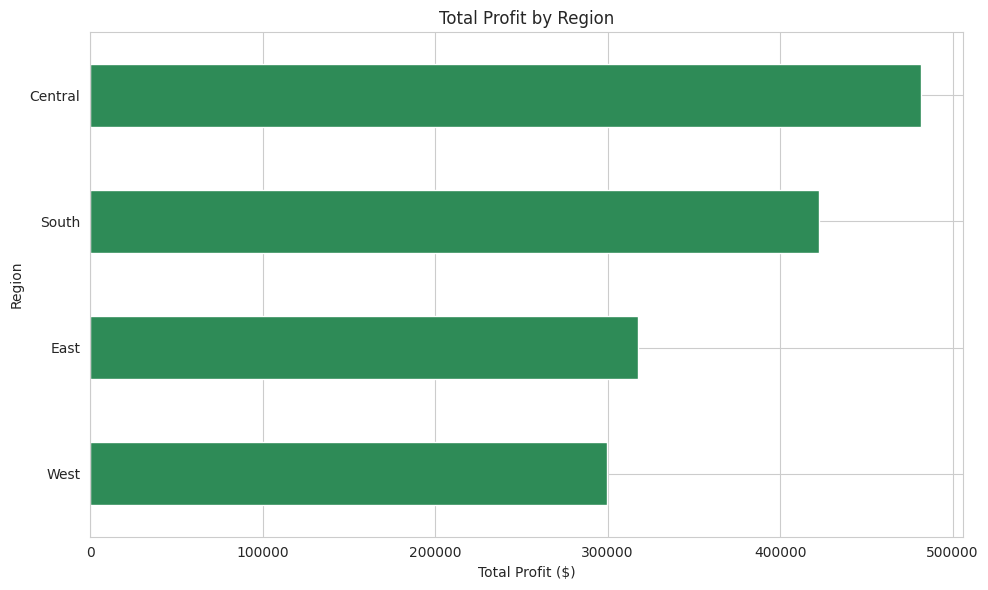

In [11]:
region_profit.sort_values().plot(kind="barh", color="seagreen")
plt.title("Total Profit by Region")
plt.xlabel("Total Profit ($)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

**Insight:**
- **Central** leads in profit too (**\$481,891.24**), consistent with its
  revenue lead from Q6 — the strongest region overall.
- The more notable finding is the **ranking shuffle below Central**:
  **South** ranks *last* in revenue (Q6) but *second* in profit here, while
  **West** ranks *second* in revenue but *last* in profit.
- This mismatch means revenue rank alone is a poor proxy for profit rank —
  South is converting its sales into profit more efficiently than West is,
  despite generating less revenue. Q8 (profit margin by region) will quantify
  this efficiency gap directly.

### Q8. Which region has the best profit margin percentage?

In [12]:
region_margin = (df.groupby("region")["profit"].sum() / df.groupby("region")["sales"].sum()) * 100
region_margin = region_margin.sort_values(ascending=False)
print(region_margin.round(2))

region
South     13.41
Central   10.25
East       9.30
West       8.21
dtype: float64


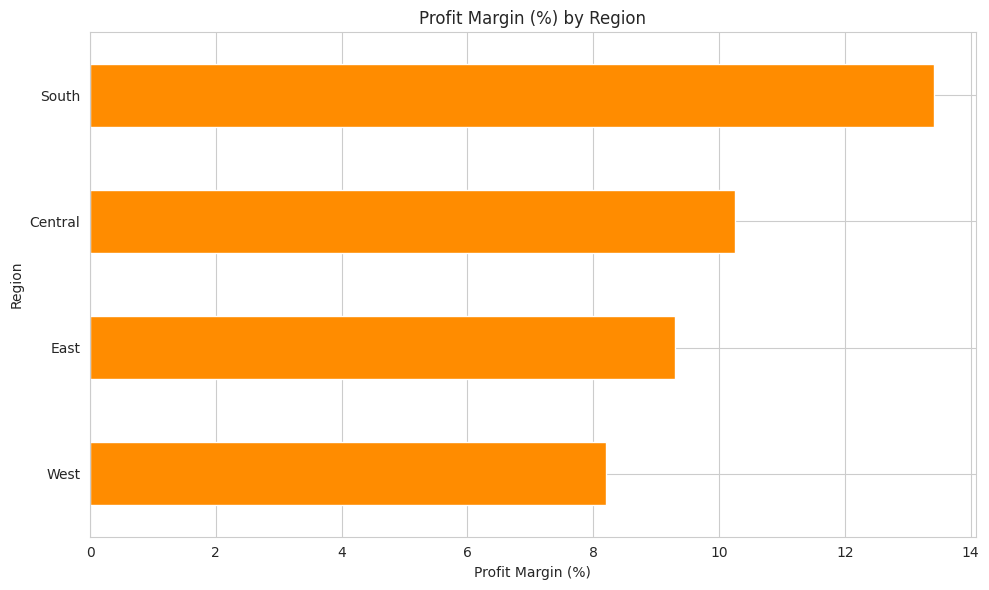

In [13]:
region_margin.sort_values().plot(kind="barh", color="darkorange")
plt.title("Profit Margin (%) by Region")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

**Insight:**
- **South** has the best profit margin at **13.41%**, despite generating the
  *least* revenue of all four regions (Q6) — it's the most efficient region
  at converting sales into profit.
- **West** is the opposite case: second-highest revenue (Q6) but the
  **worst margin at 8.21%** — nearly 5 percentage points behind South. This
  confirms West isn't a small-scale problem; it's a real efficiency gap
  worth investigating (likely tied to discounting or product mix, to be
  explored in the Discount & Profitability category).
- **Central**, the revenue and profit leader, sits in the middle on margin
  (10.25%) — its dollar dominance comes from *volume*, not from being the
  most efficient region.

### Q9. Which state is the most profitable and which state is losing us money?

In [14]:
state_profit = df.groupby("state")["profit"].sum().sort_values(ascending=False)

print("Top 5 Most Profitable States:")
print(state_profit.head(5).apply(fmt_currency))

print("\nTop 5 Least Profitable States:")
print(state_profit.tail(5).apply(fmt_currency))

Top 5 Most Profitable States:
state
Illinois      $108,532.02
Texas          $93,571.53
Ohio           $88,615.47
California     $87,355.53
New York       $86,395.96
Name: profit, dtype: object

Top 5 Least Profitable States:
state
Vermont           $6,378.93
Nevada            $3,976.83
West Virginia     $1,227.61
Delaware            $585.35
Montana          $-9,127.20
Name: profit, dtype: object


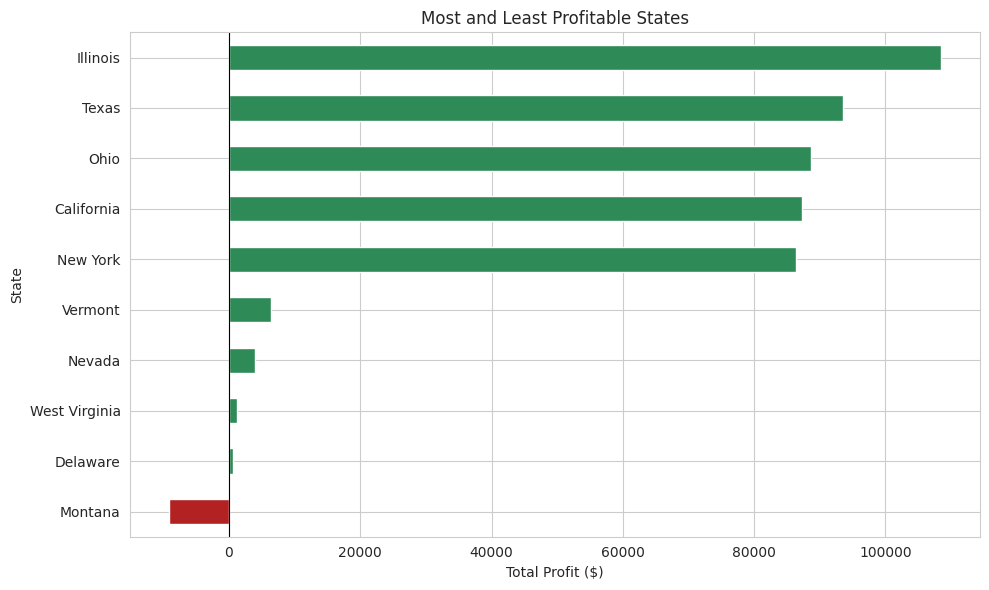

In [15]:
top_bottom = pd.concat([state_profit.head(5), state_profit.tail(5)]).sort_values()

colors = ["seagreen" if val >= 0 else "firebrick" for val in top_bottom.values]
top_bottom.plot(kind="barh", color=colors)
plt.title("Most and Least Profitable States")
plt.xlabel("Total Profit ($)")
plt.ylabel("State")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

**Insight:**
- **Illinois** is the most profitable state (**\$108,532.02**), meaningfully
  ahead of Texas, Ohio, California, and New York, which are fairly close
  to each other in the \$86K-\$94K range.
- **Montana** is the only state with a net loss (**-\$9,127.20**) — every
  other state in the bottom 5 (Vermont, Nevada, West Virginia, Delaware) is
  still profitable, just marginally.
- This means the "losing money" problem is not widespread at the state level —
  it's concentrated in a single state, Montana, rather than reflecting a
  broad geographic weakness. Worth a closer look in Q11, which asks whether
  any states lose money *despite decent sales* (Montana's small size may
  explain the loss rather than a deeper structural issue).

### Q10. Which city generates the most revenue?

In [16]:
city_revenue = df.groupby("city")["sales"].sum().sort_values(ascending=False)
print(city_revenue.head(10).apply(fmt_currency))

city
Madison           $119,942.89
San Francisco     $103,078.76
Watertown          $65,865.98
Portland           $63,281.91
Columbus           $62,854.25
Danville           $62,326.28
Mechanicsville     $62,018.16
Kent               $56,690.83
Gainesville        $54,431.43
Roseville          $53,785.89
Name: sales, dtype: object


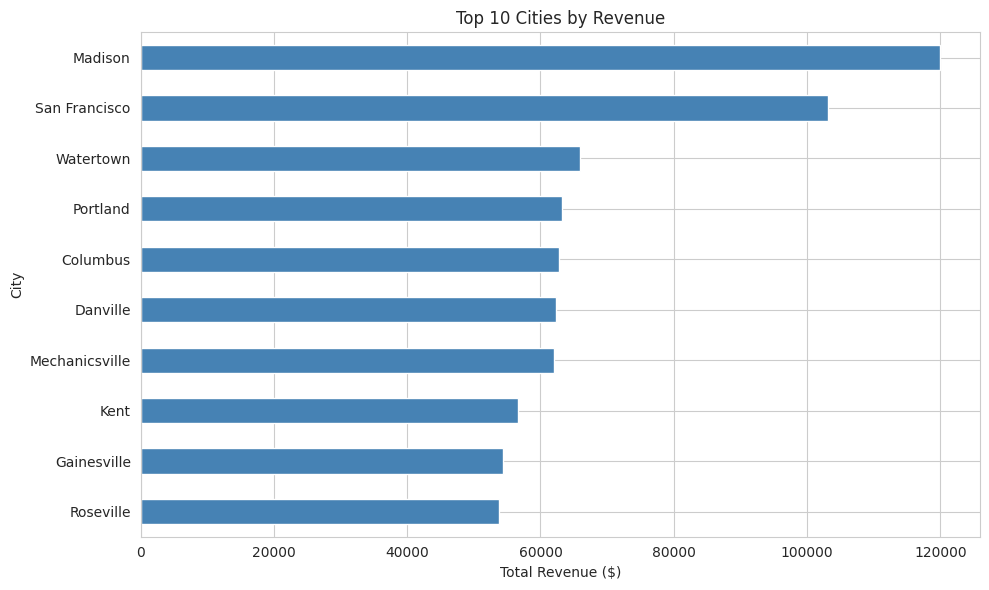

In [17]:
city_revenue.head(10).sort_values().plot(kind="barh", color="steelblue")
plt.title("Top 10 Cities by Revenue")
plt.xlabel("Total Revenue ($)")
plt.ylabel("City")
plt.tight_layout()
plt.show()

**Insight:**
- **Madison** is the top revenue-generating city (**\$119,942.89**), noticeably
  ahead of **San Francisco** (**\$103,078.76**) — the only two cities above
  the \$100K mark.
- After the top 2, revenue drops off sharply — the remaining 8 cities in the
  top 10 sit in a tighter \$53K-\$66K range, suggesting Madison and San
  Francisco are genuine standouts rather than the top of a smooth, gradual
  ranking.
- This is a useful input for Q11 next: a city or state generating strong
  revenue (like Madison) is only a good sign if that revenue is actually
  converting to profit — worth keeping in mind as we check for states that
  sell well but still lose money.

### Q11. Are there any states where we are consistently losing money despite decent sales?

In [18]:
state_summary = df.groupby("state").agg(
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum")
)
state_summary["profit_margin"] = (state_summary["total_profit"] / state_summary["total_sales"]) * 100

loss_making_states = state_summary[state_summary["total_profit"] < 0].sort_values("total_sales", ascending=False)
print(loss_making_states.apply(lambda col: col.map(fmt_currency) if col.name != "profit_margin" else col.round(2)))

        total_sales total_profit  profit_margin
state                                          
Montana  $76,071.98   $-9,127.20         -12.00


In [19]:
state_summary

,total_sales,total_profit,profit_margin
state,,,
Alabama,305010.84,53629.99,17.58
Arizona,249113.82,39829.33,15.99
Arkansas,223888.08,39850.29,17.80
California,1372210.21,87355.53,6.37
Colorado,323632.23,20386.20,6.30
Connecticut,102924.07,6885.14,6.69
Delaware,10925.66,585.35,5.36
Florida,777663.93,82571.95,10.62
Georgia,325851.94,45113.29,13.84


In [20]:
loss_making_states

,total_sales,total_profit,profit_margin
state,,,
Montana,76071.98,-9127.20,-12.00


**Insight:**
- **Montana** is the only state losing money overall, and the numbers show
  it isn't a marginal case: **\$76,071.98** in sales converted into a
  **-\$9,127.20** loss, a **-12.00% profit margin**.
- This directly answers the question: Montana had **decent sales** —
  \$76K is a real, non-trivial sales volume, not a tiny outlier state — yet
  every dollar sold actually cost the business money on average. This is a
  genuine loss-making pattern, not just low-volume noise.
- Since this is isolated to a single state rather than spread across several,
  it points to something specific happening in Montana's orders (pricing,
  discounting, or product mix) rather than a systemic regional issue — a
  good candidate for deeper investigation outside the scope of this notebook's
  39 questions, or as a flagged limitation.

**Category 2 Summary:**

Regional performance shows a consistent leader in **Central** (highest revenue
and profit), while **South** stands out for efficiency — the best profit margin
despite the lowest revenue. At the state level, profitability is broadly healthy:
**Illinois** leads, and only **Montana** posts a net loss, doing so despite a
respectable \$76K in sales, making it a clear and isolated problem area rather
than a regional trend. **Madison** leads all cities in revenue, well ahead of the
next closest city. Together, these findings suggest the business's regional
performance is generally sound, with money-losing pockets being the exception
rather than the rule.

## Category 3: Product & Category Analysis

**Business Question:** "We need to know what to sell more of and what to
stop pushing."

This section examines performance at the product category and sub-category
level to identify which product lines drive revenue, which are genuinely
profitable, and which may be dragging down overall performance.

### Q12. Which category generates the most revenue?

In [21]:
category_revenue = df.groupby("product_category")["sales"].sum().sort_values(ascending=False)
print(category_revenue.apply(fmt_currency))

product_category
Technology         $5,984,248.18
Furniture          $5,178,590.54
Office Supplies    $3,752,762.10
Name: sales, dtype: object


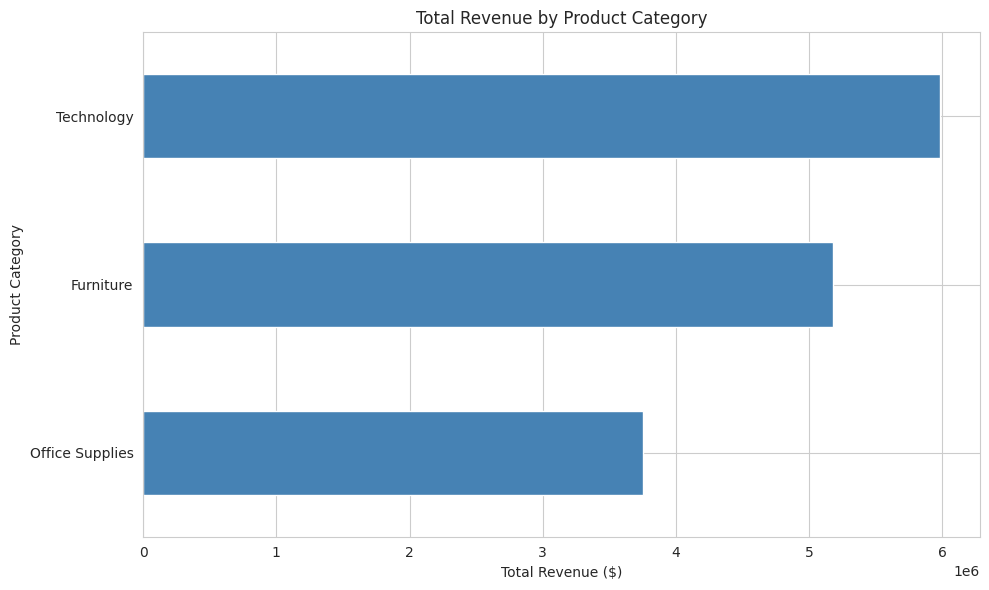

In [22]:
category_revenue.sort_values().plot(kind="barh", color="steelblue")
plt.title("Total Revenue by Product Category")
plt.xlabel("Total Revenue ($)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

**Insight:**
- **Technology** leads in revenue (**\$5.98M**), narrowly ahead of
  **Furniture** (**\$5.18M**), with **Office Supplies** trailing at
  **\$3.75M**.
- This is worth pairing with the Notebook 3 finding that **Office Supplies**
  is the priority problem category for profitability, despite having the
  **highest order volume**. Revenue here shows Office Supplies actually
  generates the *least* total revenue of the three — meaning its high order
  count comes from many smaller-value orders, not big-ticket sales. Q13 next
  will check whether this lower-revenue category is also the least
  profitable, or whether the story is more nuanced.

### Q13. Which category is the most profitable and which has the worst profit margin?

In [23]:
category_summary = df.groupby("product_category").agg(
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum")
)
category_summary["profit_margin"] = (category_summary["total_profit"] / category_summary["total_sales"]) * 100
category_summary = category_summary.sort_values("total_profit", ascending=False)

print(category_summary)

                  total_sales  total_profit  profit_margin
product_category                                          
Technology         5984248.18     886313.52          14.81
Office Supplies    3752762.10     518021.46          13.80
Furniture          5178590.54     117432.99           2.27


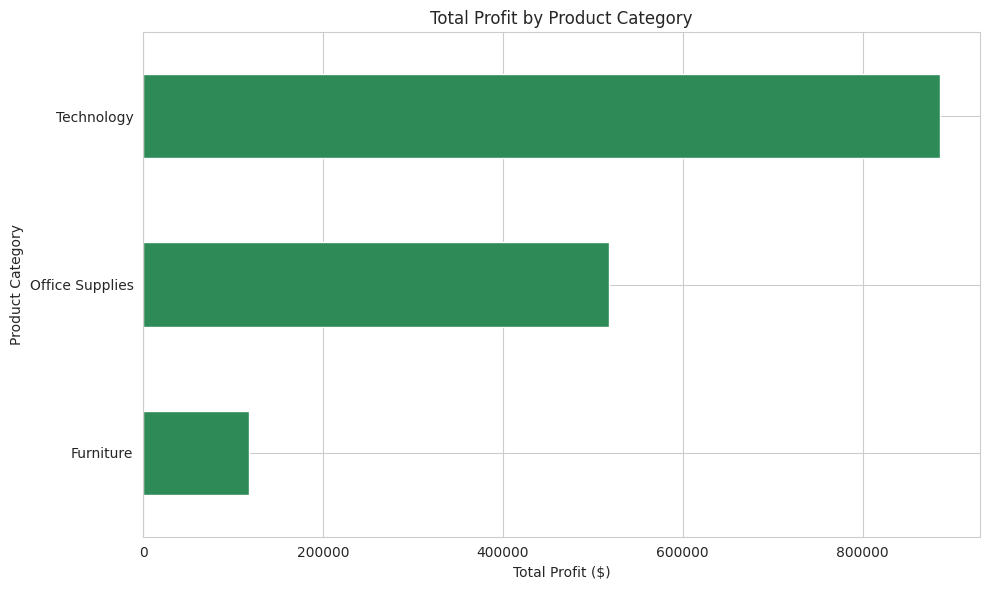

In [24]:
category_summary["total_profit"].sort_values().plot(kind="barh", color="seagreen")
plt.title("Total Profit by Product Category")
plt.xlabel("Total Profit ($)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

**Insight:**
- **Technology** is both the highest-revenue *and* most profitable category
  (**\$886,313.52**, **14.81%** margin) — a genuinely strong performer,
  consistent with the Notebook 3 finding that it was the strongest category
  overall.
- **Furniture** is the clear problem here — despite generating the *second-highest
  revenue* (\$5.18M, close to Technology's \$5.98M), it produces only
  **\$117,432.99** in profit, a razor-thin **2.27% margin**. This is a
  significant finding: Furniture sells nearly as much as Technology but
  converts almost none of it into profit.
- This shifts the earlier Notebook 3 narrative slightly: Office Supplies was
  flagged as the priority problem due to volume and severity of individual
  losses, but on a **category-wide margin basis**, **Furniture is actually the
  weakest performer** (2.27% vs. Office Supplies' 13.80%). Both categories
  matter, but for different reasons — Office Supplies for its cumulative small
  losses across many orders, Furniture for a structurally poor margin despite
  strong revenue.

### Q14. Which sub-category has the highest and lowest (or negative) profit?

In [25]:
subcat_profit = df.groupby("product_sub_category")["profit"].sum().sort_values(ascending=False)

print("Top 5 Most Profitable Sub-Categories:")
print(subcat_profit.head(5).apply(fmt_currency))

print("\nBottom 5 Sub-Categories:")
print(subcat_profit.tail(5).apply(fmt_currency))

Top 5 Most Profitable Sub-Categories:
product_sub_category
Telephones and Communication      $316,951.64
Office Machines                   $307,712.93
Binders and Binder Accessories    $307,413.42
Copiers and Fax                   $167,361.46
Chairs & Chairmats                $149,649.73
Name: profit, dtype: object

Bottom 5 Sub-Categories:
product_sub_category
Storage & Organization             $6,664.15
Rubber Bands                        $-102.67
Scissors, Rulers and Trimmers     $-7,799.25
Bookcases                        $-33,582.13
Tables                           $-99,062.53
Name: profit, dtype: object


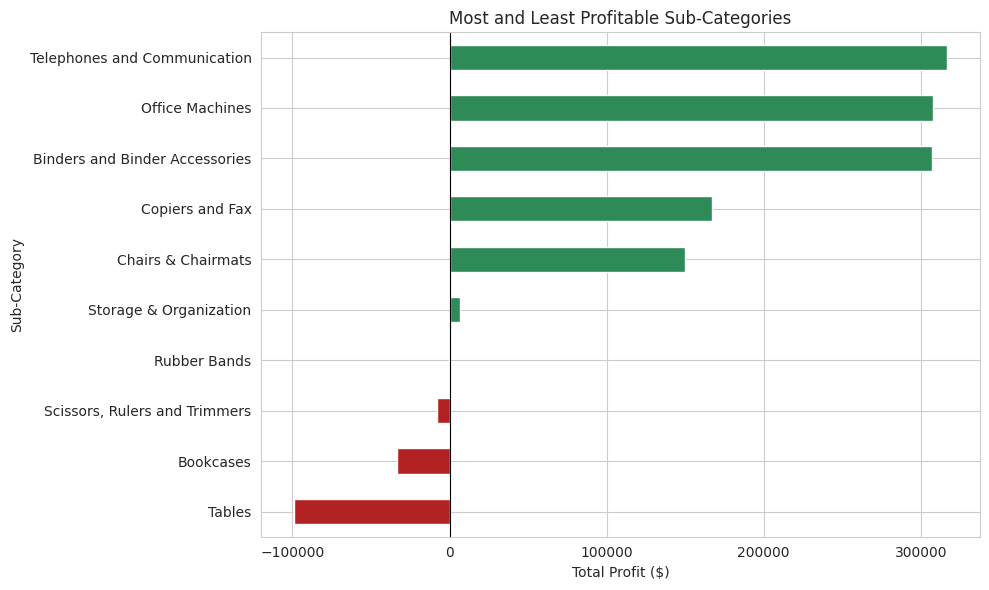

In [26]:
top_bottom_subcat = pd.concat([subcat_profit.head(5), subcat_profit.tail(5)]).sort_values()

colors = ["seagreen" if val >= 0 else "firebrick" for val in top_bottom_subcat.values]
top_bottom_subcat.plot(kind="barh", color=colors)
plt.title("Most and Least Profitable Sub-Categories")
plt.xlabel("Total Profit ($)")
plt.ylabel("Sub-Category")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

**Insight:**
- **Telephones and Communication** is the most profitable sub-category
  (**\$316,951.64**), closely followed by **Office Machines** and
  **Binders and Binder Accessories** — all three well above \$300K.
- **Tables** is the single biggest problem in the dataset (**-\$99,062.53**),
  followed by **Bookcases** (**-\$33,582.13**) — both are Furniture
  sub-categories, which directly explains the weak 2.27% category-wide margin
  found in Q13. Furniture's poor performance isn't spread evenly; it's
  concentrated in these two sub-categories specifically.
- **Scissors, Rulers and Trimmers** (**-\$7,799.25**) and **Rubber Bands**
  (**-\$102.67**) are Office Supplies sub-categories running small losses —
  consistent with Notebook 3's finding that Office Supplies' issue is many
  small losses across volume, not one catastrophic sub-category.
- Together, this pinpoints exactly where the two problem categories from Q13
  are bleeding money: **Furniture via Tables and Bookcases**, **Office
  Supplies via smaller, more distributed losses**.

### Q15. What are the top 10 best-selling products by revenue?

In [27]:
product_revenue = df.groupby("product_name")["sales"].sum().sort_values(ascending=False)
print(product_revenue.head(10).apply(fmt_currency))

product_name
Global Troy™ Executive Leather Low-Back Tilter                   $275,941.52
Polycom ViewStation™ ISDN Videoconferencing Unit                 $255,303.97
Canon PC940 Copier                                               $210,910.68
Riverside Palais Royal Lawyers Bookcase, Royale Cherry Finish    $206,494.13
Hewlett Packard LaserJet 3310 Copier                             $194,880.35
Bretford CR8500 Series Meeting Room Furniture                    $147,412.21
Sharp AL-1530CS Digital Copier                                   $130,046.81
Hewlett-Packard cp1700 [D, PS] Series Color Inkjet Printers      $128,100.43
GBC DocuBind 200 Manual Binding Machine                          $120,342.74
Canon imageCLASS 2200 Advanced Copier                            $114,173.41
Name: sales, dtype: object


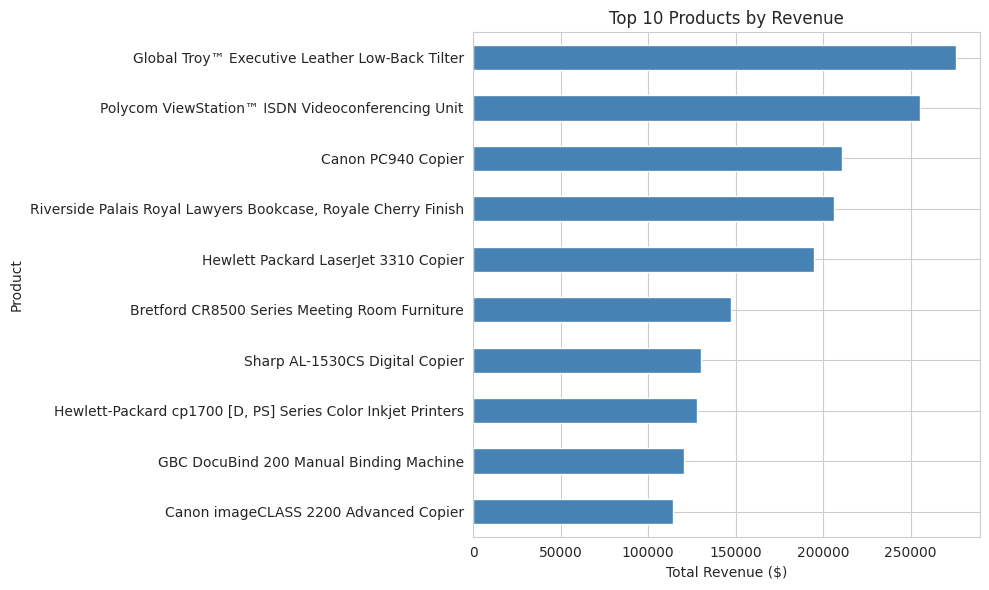

In [28]:
product_revenue.head(10).sort_values().plot(kind="barh", color="steelblue")
plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue ($)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

**Insight:**
- The **Global Troy™ Executive Leather Low-Back Tilter** is the single
  highest-revenue product (**\$275,941.52**), followed by the **Polycom
  ViewStation™ ISDN Videoconferencing Unit** (**\$255,303.97**).
- The list is dominated by **Technology** (copiers, printers, videoconferencing
  units) and higher-end **Furniture** items — consistent with Q12's finding
  that Technology and Furniture are the top two revenue categories.
- Notably, a **Riverside Palais Royal Lawyers Bookcase** appears at #4
  (\$206,494.13) — high revenue despite Bookcases being flagged in Q14 as one
  of the least profitable sub-categories overall. This is an early signal
  worth tracking into Q17 (products with high sales but negative profit),
  since a specific bookcase model selling well doesn't guarantee the
  sub-category as a whole is profitable.

### Q16. What are the top 10 most profitable products?

In [29]:
product_profit = df.groupby("product_name")["profit"].sum().sort_values(ascending=False)
print(product_profit.head(10).apply(fmt_currency))

product_name
Global Troy™ Executive Leather Low-Back Tilter                                 $79,284.78
Hewlett Packard LaserJet 3310 Copier                                           $73,299.60
Hewlett-Packard cp1700 [D, PS] Series Color Inkjet Printers                    $55,281.39
GBC DocuBind 200 Manual Binding Machine                                        $50,462.51
Canon PC940 Copier                                                             $47,705.84
Fellowes PB300 Plastic Comb Binding Machine                                    $45,927.86
Hewlett-Packard Deskjet 1220Cse Color Inkjet Printer                           $44,740.41
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    $32,566.56
GBC DocuBind TL300 Electric Binding System                                     $32,022.88
Smead Adjustable Mobile File Trolley with Lockable Top                         $31,939.21
Name: profit, dtype: object


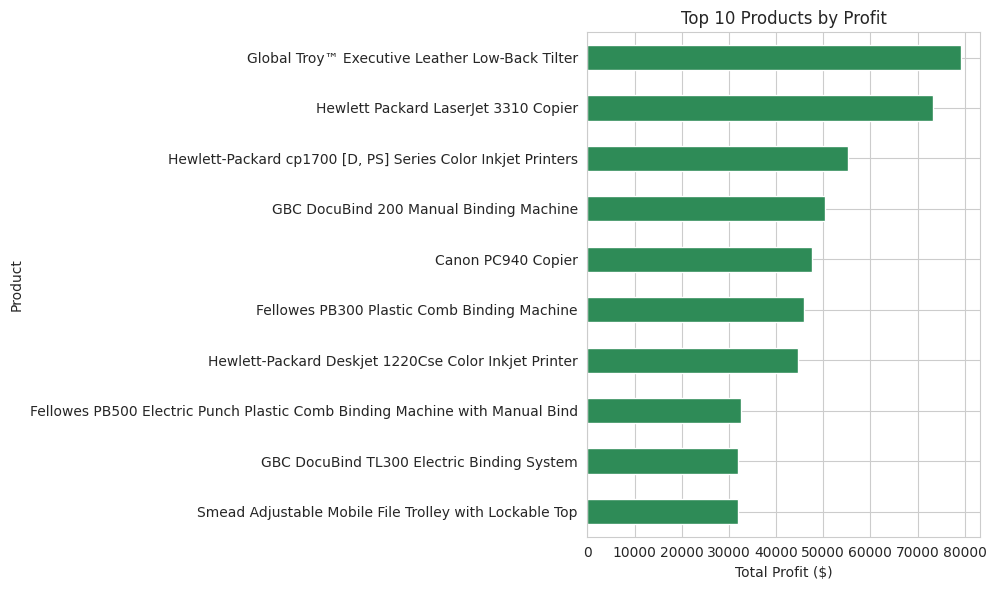

In [30]:
product_profit.head(10).sort_values().plot(kind="barh", color="seagreen")
plt.title("Top 10 Products by Profit")
plt.xlabel("Total Profit ($)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

**Insight:**
- The **Global Troy™ Executive Leather Low-Back Tilter** tops both revenue
  (Q15) and profit (**\$79,284.78**) — a genuinely strong, consistent
  performer.
- Beyond that, the two lists diverge: the **Polycom ViewStation™** was #2 in
  revenue but doesn't appear in the top 10 for profit, while binding machines
  and printers (Fellowes, GBC, Hewlett-Packard) dominate the profit list
  despite not all being top-10 by revenue. This shows high revenue does not
  reliably predict high profit at the product level, echoing the same pattern
  already seen at the region and category levels.
- Every product in this top-10 profit list belongs to **Technology** or
  **Office Supplies** — no Furniture product appears, reinforcing Q13's
  finding that Furniture struggles to convert its strong revenue into real
  profit.

### Q17. Are there products with high sales but negative profit (selling at a loss)?

In [31]:
product_summary = df.groupby("product_name").agg(
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum")
)

high_sales_loss = product_summary[
    (product_summary["total_profit"] < 0) &
    (product_summary["total_sales"] > product_summary["total_sales"].median())
].sort_values("total_sales", ascending=False)

print(high_sales_loss.head(10).apply(lambda col: col.map(fmt_currency)))

                                                    total_sales total_profit
product_name                                                                
Polycom ViewStation™ ISDN Videoconferencing Unit    $255,303.97  $-17,771.27
Bretford CR8500 Series Meeting Room Furniture       $147,412.21   $-1,989.86
Canon imageCLASS 2200 Advanced Copier               $114,173.41  $-31,885.68
Chromcraft Bull-Nose Wood 48" x 96" Rectangular...  $106,628.99   $-6,344.64
BoxOffice By Design Rectangular and Half-Moon M...  $104,483.14  $-14,938.69
Hon 94000 Series Round Tables                       $102,005.84   $-4,497.48
Bretford Rectangular Conference Table Tops           $91,729.64   $-2,795.17
Polycom ViewStation™ Adapter H323 Videoconferen...   $88,273.27   $-1,007.49
Epson DFX-8500 Dot Matrix Printer                    $85,975.08  $-29,400.34
Global High-Back Leather Tilter, Burgundy            $82,752.20  $-30,518.90


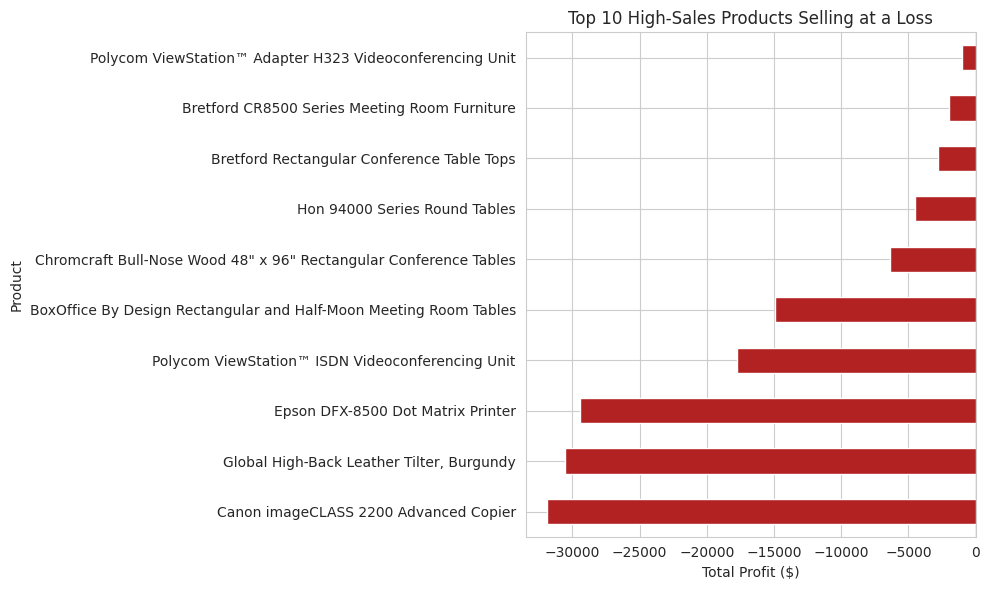

In [32]:
high_sales_loss.head(10)["total_profit"].sort_values().plot(kind="barh", color="firebrick")
plt.title("Top 10 High-Sales Products Selling at a Loss")
plt.xlabel("Total Profit ($)")
plt.ylabel("Product")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

**Insight:**
- Yes — several high-selling products are actively losing money. The
  **Polycom ViewStation™ ISDN Videoconferencing Unit** is the most striking
  case: **\$255,303.97** in sales (Q15's #2 best-seller by revenue) yet a
  **-\$17,771.27** loss.
- The worst *dollar* losses among high-sellers are the **Global High-Back
  Leather Tilter** (-\$30,518.90), **Epson DFX-8500 Dot Matrix Printer**
  (-\$29,400.34), and **Canon imageCLASS 2200 Advanced Copier** (-\$31,885.68)
  — all three losing over \$100 for every \$1,000 in sales they generate.
- This list is a mix of **Furniture and Technology** products, confirming
  that the profitability problem isn't confined to one category — it can
  affect even strong revenue generators from categories that otherwise
  perform well (Technology was the top category by margin in Q13).
- This is a direct, actionable finding: these are prime candidates for
  **pricing review or discount policy changes**, since they combine real
  customer demand (high sales) with a structural loss on every unit sold.

### Q18. Which sub-categories drag down overall profitability?

In [33]:
subcat_summary = df.groupby("product_sub_category").agg(
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum"),
    order_count=("order_id", "nunique")
)
subcat_summary["profit_margin"] = (subcat_summary["total_profit"] / subcat_summary["total_sales"]) * 100

dragging_subcats = subcat_summary[subcat_summary["total_profit"] < 0].sort_values("total_profit")
print(dragging_subcats)

                               total_sales  total_profit  order_count  \
product_sub_category                                                    
Tables                          1896008.14     -99062.53          355   
Bookcases                        822652.04     -33582.13          188   
Scissors, Rulers and Trimmers     80996.31      -7799.25          144   
Rubber Bands                      15006.63       -102.67          178   

                               profit_margin  
product_sub_category                          
Tables                                 -5.22  
Bookcases                              -4.08  
Scissors, Rulers and Trimmers          -9.63  
Rubber Bands                           -0.68  


**Insight:**
- Four sub-categories drag down overall profitability, all already surfaced
  in Q14, but now with volume context: **Tables** (-\$99,062.53 across 355
  orders, -5.22% margin), **Bookcases** (-\$33,582.13 across 188 orders,
  -4.08% margin), **Scissors, Rulers and Trimmers** (-\$7,799.25 across 144
  orders, -9.63% margin), and **Rubber Bands** (-\$102.67 across 178 orders,
  -0.68% margin).
- **Tables** is the most damaging on every measure: the largest dollar loss,
  the highest order count among losers, and a meaningfully negative margin —
  this is not a handful of bad transactions, but a pattern spread across 355
  separate orders, meaning the problem is structural (likely pricing or cost
  of the product line) rather than a few anomalies.
- **Scissors, Rulers and Trimmers** has the *worst percentage margin*
  (-9.63%) despite a much smaller dollar loss — every sale in this
  sub-category loses money proportionally, even though the total dollars
  involved are small.
- **Rubber Bands** is a near-break-even case (-0.68% margin, -\$102.67 total)
  — technically a loss, but negligible in practice; not a priority.
- Overall: **Tables and Bookcases (both Furniture)** are the biggest and most
  urgent drag on profitability, both in dollar terms and in order volume —
  directly explaining why Furniture posted the weakest category margin in Q13.

**Category 3 Summary:**

Technology leads in both revenue and profit, while Furniture — despite
strong revenue nearly matching Technology's — converts almost none of it
into profit, driven almost entirely by **Tables** and **Bookcases**. Several
individual high-selling products (including a top revenue generator, the
Polycom ViewStation™) are quietly selling at a loss, cutting across both
Furniture and Technology. These findings sharpen the Notebook 3 view: Office
Supplies remains a volume-driven, distributed problem, while Furniture has
emerged as a concentrated, structural one centered on two specific
sub-categories.

## Category 4: Customer Analysis

**Business Question:** "We need to understand who our customers are and
which ones matter most to the business."

This section looks at customer segments and individual customers to identify
who drives the most revenue and profit, and who may be high-revenue but
unprofitable.

### Q19. Which customer segment generates the most revenue?

In [34]:
segment_revenue = df.groupby("customer_segment")["sales"].sum().sort_values(ascending=False)
print(segment_revenue.apply(fmt_currency))

customer_segment
Corporate         $5,498,904.88
Home Office       $3,564,763.88
Consumer          $3,063,611.08
Small Business    $2,788,320.99
Name: sales, dtype: object


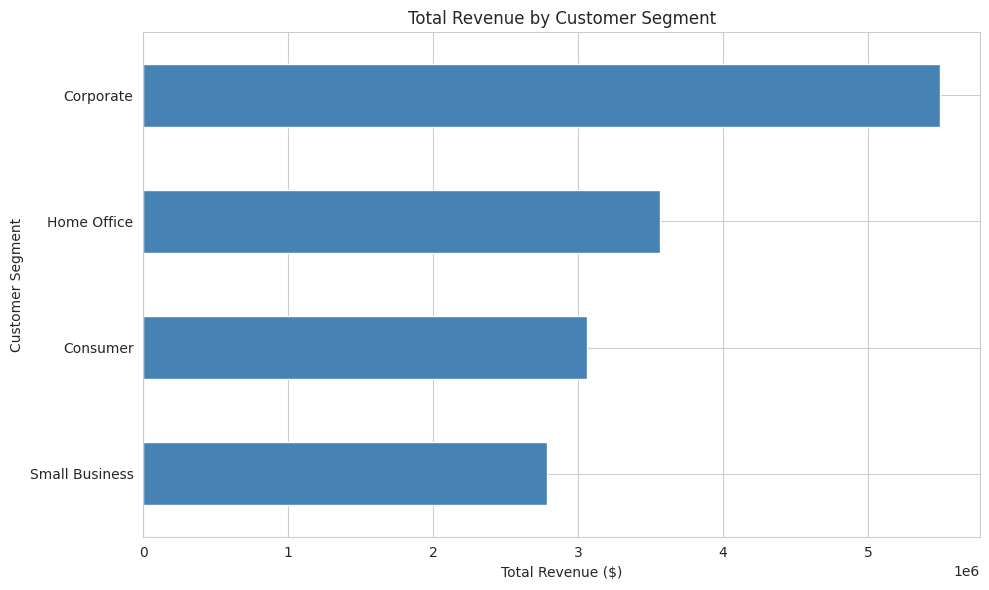

In [35]:
segment_revenue.sort_values().plot(kind="barh", color="steelblue")
plt.title("Total Revenue by Customer Segment")
plt.xlabel("Total Revenue ($)")
plt.ylabel("Customer Segment")
plt.tight_layout()
plt.show()

**Insight:**
- **Corporate** is the clear revenue leader (**\$5.50M**), generating nearly
  as much as the next two segments combined (Home Office + Consumer =
  \$6.63M).
- **Small Business** brings in the least revenue (**\$2.79M**), roughly half
  of Corporate's total — worth checking in Q20 whether this ranking holds
  for profit too, or whether a smaller-revenue segment turns out to be more
  efficient, echoing the pattern already seen at the regional level (South).

### Q20. Which customer segment is most profitable?

In [36]:
segment_summary = df.groupby("customer_segment").agg(
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum")
)
segment_summary["profit_margin"] = (segment_summary["total_profit"] / segment_summary["total_sales"]) * 100
segment_summary = segment_summary.sort_values("total_profit", ascending=False)

print(segment_summary)

                  total_sales  total_profit  profit_margin
customer_segment                                          
Corporate          5498904.88     599745.92          10.91
Home Office        3564763.88     318354.10           8.93
Small Business     2788320.99     315707.96          11.32
Consumer           3063611.08     287959.98           9.40


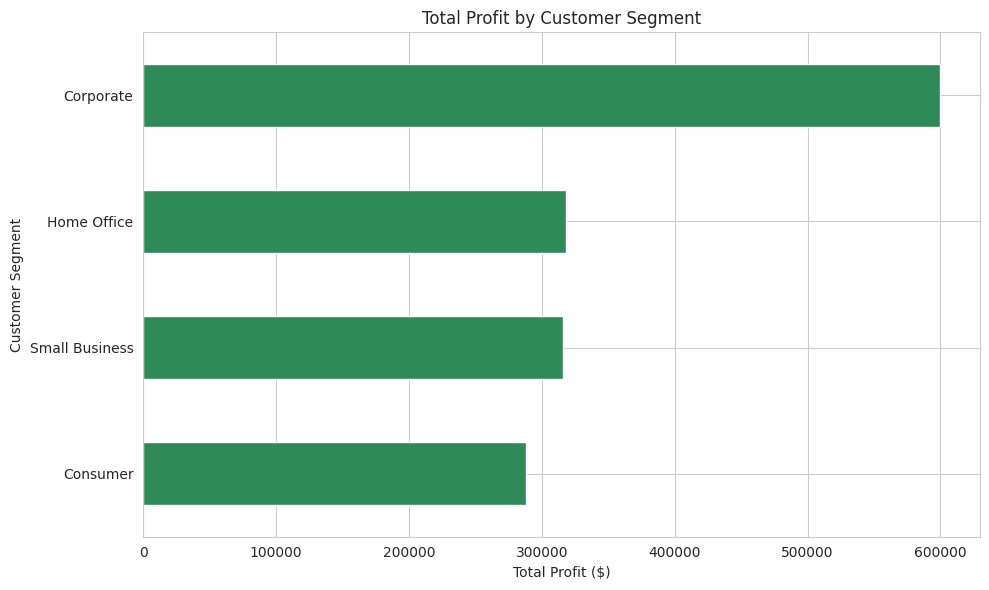

In [37]:
segment_summary["total_profit"].sort_values().plot(kind="barh", color="seagreen")
plt.title("Total Profit by Customer Segment")
plt.xlabel("Total Profit ($)")
plt.ylabel("Customer Segment")
plt.tight_layout()
plt.show()

**Insight:**
- **Corporate** is the most profitable segment in raw dollars (**\$599,745.92**),
  consistent with its revenue lead in Q19 — the scale advantage carries through.
- On **margin**, however, **Small Business** is actually the most efficient
  segment (**11.32%**), edging out Corporate (10.91%) despite generating the
  least revenue of the four (Q19). This mirrors the exact pattern seen with
  South region in Q8 — smaller in scale, but better at converting sales into
  profit.
- **Home Office** has the weakest margin (**8.93%**), meaning it converts
  sales into profit less efficiently than any other segment, despite solid
  revenue (\$3.56M, second-highest).
- Bottom line: Corporate should remain the priority for scale (it drives the
  most total profit), but Small Business's efficiency is worth understanding
  — if that margin could be paired with more volume, it could meaningfully
  boost overall profitability.

### Q21. Who are the top 10 customers by total revenue?

In [38]:
customer_revenue = df.groupby("customer_name")["sales"].sum().sort_values(ascending=False)
print(customer_revenue.head(10).apply(fmt_currency))

customer_name
Emily Phan           $117,124.44
Deborah Brumfield     $97,433.14
Roy Skaria            $92,542.15
Sylvia Foulston       $88,875.76
Grant Carroll         $88,417.00
Alejandro Grove       $83,561.93
Darren Budd           $81,577.34
Julia Barnett         $80,044.45
John Lucas            $79,696.19
Liz MacKendrick       $76,306.43
Name: sales, dtype: object


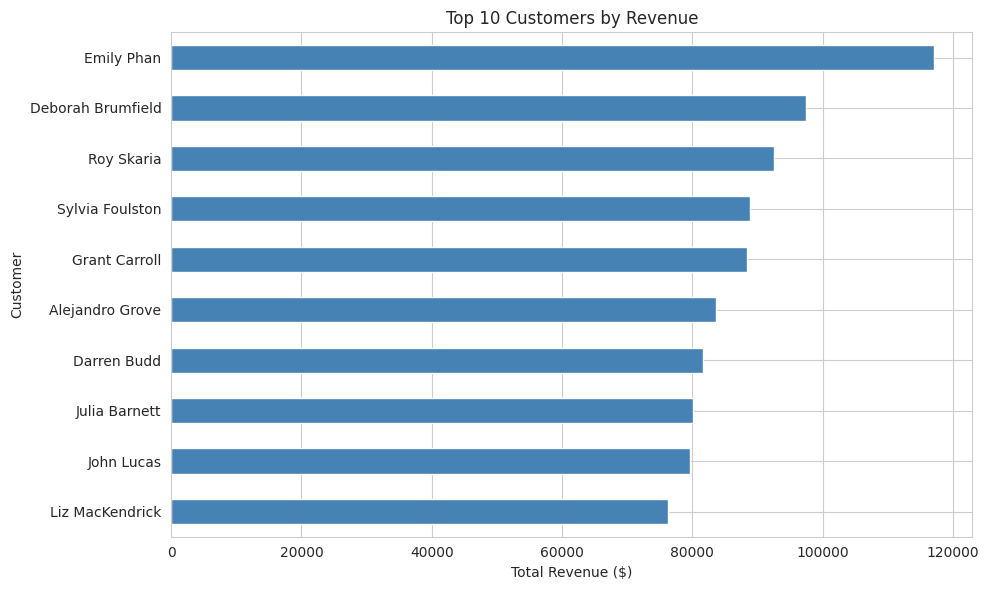

In [39]:
customer_revenue.head(10).sort_values().plot(kind="barh", color="steelblue")
plt.title("Top 10 Customers by Revenue")
plt.xlabel("Total Revenue ($)")
plt.ylabel("Customer")
plt.tight_layout()
plt.show()

**Insight:**
- **Emily Phan** is the top customer by revenue (**\$117,124.44**),
  meaningfully ahead of **Deborah Brumfield** (**\$97,433.14**) in second.
- The top 10 customers range from roughly \$76K to \$117K each — a relatively
  tight cluster rather than one dominant outlier, suggesting revenue isn't
  overly concentrated in a single account.
- These are the accounts most worth retaining relationship-wise from a pure
  revenue standpoint, but Q22 (profit) will determine whether high spend
  actually translates to high value for the business.

### Q22. Who are the top 10 customers by total profit?

In [40]:
customer_profit = df.groupby("customer_name")["profit"].sum().sort_values(ascending=False)
print(customer_profit.head(10).apply(fmt_currency))

customer_name
Emily Phan           $34,005.45
Deborah Brumfield    $31,121.22
Grant Carroll        $27,977.28
Karen Carlisle       $21,731.52
Alejandro Grove      $20,588.92
Liz MacKendrick      $20,397.24
John Stevenson       $18,849.93
Clytie Kelty         $18,792.81
Raymond Book         $18,760.59
Logan Haushalter     $18,348.54
Name: profit, dtype: object


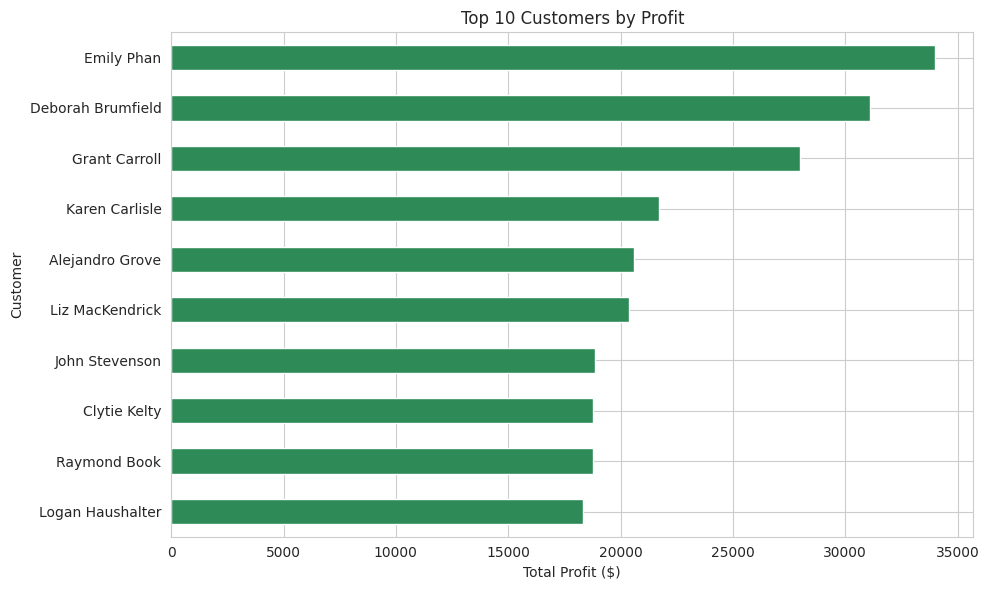

In [41]:
customer_profit.head(10).sort_values().plot(kind="barh", color="seagreen")
plt.title("Top 10 Customers by Profit")
plt.xlabel("Total Profit ($)")
plt.ylabel("Customer")
plt.tight_layout()
plt.show()

**Insight:**
- **Emily Phan** and **Deborah Brumfield** top both lists — the two
  strongest customers by revenue (Q21) are also the two most profitable,
  making them clear priority accounts for retention.
- Beyond the top 2, the lists diverge: **Roy Skaria** and **Sylvia Foulston**
  were top-5 by revenue but don't appear in the top-10 profit list, while
  **Karen Carlisle**, **John Stevenson**, **Clytie Kelty**, **Raymond Book**,
  and **Logan Haushalter** rank highly on profit without being top-10
  revenue generators — meaning these customers may buy less overall, but
  what they do buy is disproportionately profitable.
- This reinforces the pattern seen throughout the notebook: revenue rank and
  profit rank frequently diverge, so a "top customer" list should really be
  two separate lists depending on whether the business goal is growth
  (revenue) or margin (profit).

### Q23. How many unique customers does the business have?

In [42]:
unique_customers = df["customer_name"].nunique()
print(f"Total Unique Customers: {unique_customers:,}")

Total Unique Customers: 795


**Insight:**
- The business serves **795 unique customers** across 2009-2012, generating
  5,496 total orders (Q1) — an average of roughly **6-7 orders per customer**
  over the four-year period.
- With total revenue of \$14.92M (Q1) spread across 795 customers, this gives
  a rough benchmark of about **\$18,762 in average lifetime revenue per
  customer** — useful context for judging how exceptional the top-10
  customers from Q21 (\$76K-\$117K each) really are: several times the
  typical customer's total spend.

### Q24. Are there customers who generate high revenue but negative profit?

In [43]:
customer_summary = df.groupby("customer_name").agg(
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum")
)

high_rev_loss_customers = customer_summary[
    (customer_summary["total_profit"] < 0) &
    (customer_summary["total_sales"] > customer_summary["total_sales"].median())
].sort_values("total_sales", ascending=False)

print(high_rev_loss_customers.head(10).apply(lambda col: col.map(fmt_currency)))

               total_sales total_profit
customer_name                          
Julia Barnett   $80,044.45   $-1,956.09
Matt Abelman    $60,962.35   $-2,256.84
Carlos Soltero  $55,575.09       $-9.17
Jack Lebron     $51,155.80   $-1,498.29
Roy Phan        $46,546.17   $-9,613.99
Nicole Brennan  $44,184.60     $-925.27
Julia West      $44,021.42  $-14,154.29
Clay Cheatham   $42,255.17   $-3,799.77
Sally Knutson   $38,449.29     $-953.29
Maribeth Dona   $37,359.52   $-3,418.38


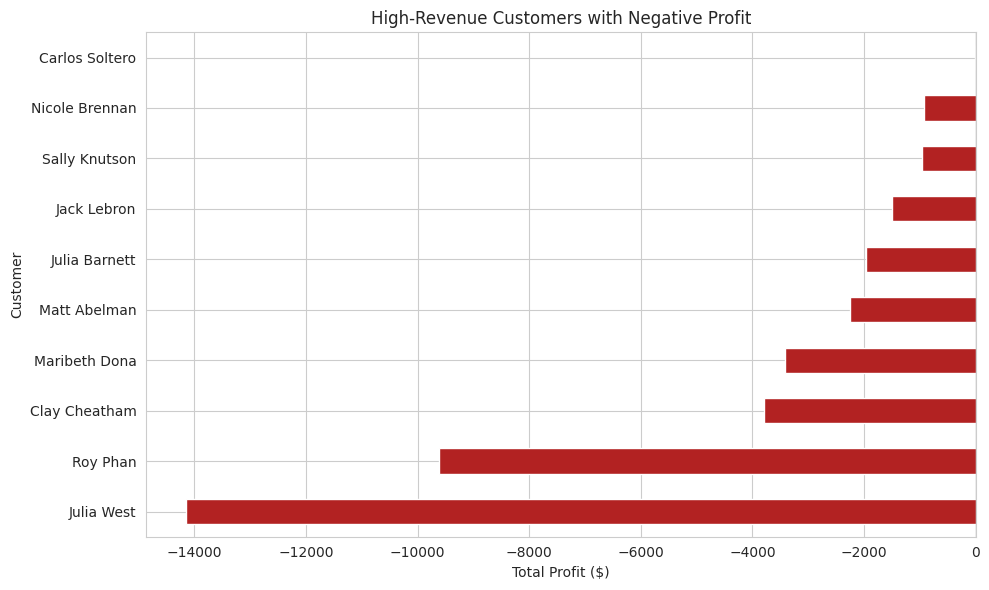

In [44]:
high_rev_loss_customers.head(10)["total_profit"].sort_values().plot(kind="barh", color="firebrick")
plt.title("High-Revenue Customers with Negative Profit")
plt.xlabel("Total Profit ($)")
plt.ylabel("Customer")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

**Insight:**
- Yes — several high-spending customers are net unprofitable. **Julia West**
  stands out with the largest loss (**-\$14,154.29**) despite solid revenue
  (\$44,021.42), while **Roy Phan** also shows a significant loss
  (**-\$9,613.99**) on \$46,546.17 in sales.
- Notably, **Julia Barnett** appeared in the Q21 top-10 revenue list
  (\$80,044.45) but is *also* net unprofitable here (-\$1,956.09) — a direct
  overlap showing that even a top-line "best customer" isn't automatically
  a good one for the business once profit is considered.
- **Carlos Soltero** is essentially breakeven (-\$9.17 on over \$55K in sales)
  — not a real concern, just technically negative.
- These accounts are strong candidates for a pricing or discount review: they
  clearly have demand and spend real money, but current terms are converting
  that spend into a loss rather than profit — a fixable pattern rather than a
  customer relationship problem.

**Category 4 Summary:**

Corporate leads customer segments in both revenue and profit, but Small
Business is the most efficient segment by margin. At the individual level,
Emily Phan and Deborah Brumfield are the strongest customers on both revenue
and profit, while several other high-revenue customers — including Q21's own
Julia Barnett — are quietly unprofitable, echoing the same "high revenue does
not guarantee high profit" pattern seen across regions, categories, and
products throughout this notebook.

## Category 5: Discount & Profitability

**Business Question:** "We want to understand whether our discounting
strategy is helping or hurting profitability."

This section examines the relationship between discounting and profit,
building on the Notebook 3 finding that discount level has near-zero
correlation with profit or profit margin.

### Q25. What is the relationship between discount percentage and profit?

In [45]:
discount_profit_corr = df["discount"].corr(df["profit"])
discount_margin_corr = df["discount"].corr(df["profit_margin"])

print(f"Correlation (Discount vs Profit)        : {discount_profit_corr:.3f}")
print(f"Correlation (Discount vs Profit Margin) : {discount_margin_corr:.3f}")

Correlation (Discount vs Profit)        : -0.037
Correlation (Discount vs Profit Margin) : -0.058


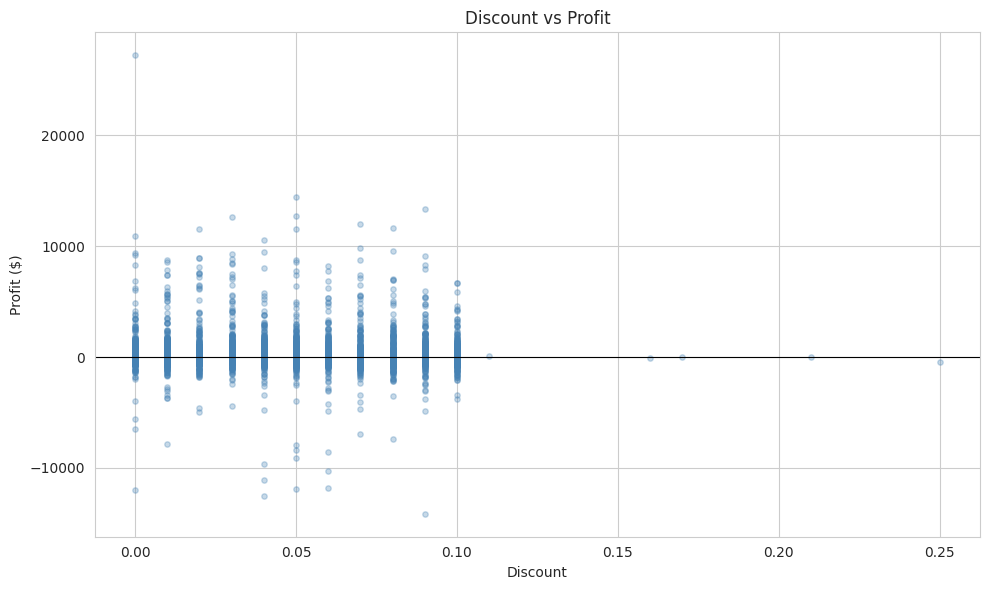

In [46]:
plt.scatter(df["discount"], df["profit"], alpha=0.3, color="steelblue", s=15)
plt.title("Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit ($)")
plt.axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

**Insight:**
- Both correlations are very close to zero (**-0.037** with profit,
  **-0.058** with profit margin) — statistically, there is essentially
  **no meaningful relationship** between discount level and profit.
- This directly answers the question: **no, higher discounts do not reliably
  mean lower profit.** If discounting were a real driver of losses, we'd
  expect a correlation closer to -0.5 or beyond; a value this close to zero
  means discount level explains almost none of the variation in profit.
- This confirms the Notebook 3 finding using the actual business-question
  framing: the root cause of unprofitable orders lies elsewhere — most likely
  product-level pricing and cost structure (as seen with Tables, Bookcases,
  and several specific high-revenue products in Q14/Q17), not the discount
  policy itself.
- The scatter plot supports this: profit values scatter widely across every
  discount level, with no visible downward slope as discount increases —
  losses and gains happen at low, medium, and high discounts alike.

### Q26. Which sub-categories receive the highest average discounts?

In [47]:
subcat_discount = df.groupby("product_sub_category")["discount"].mean().sort_values(ascending=False)
print((subcat_discount * 100).round(2).astype(str) + "%")

product_sub_category
Rubber Bands                      5.15%
Copiers and Fax                   5.15%
Pens & Art Supplies               5.13%
Storage & Organization            5.11%
Appliances                        5.06%
Office Machines                   5.05%
Binders and Binder Accessories    5.04%
Chairs & Chairmats                5.03%
Tables                            4.99%
Labels                            4.95%
Paper                             4.94%
Scissors, Rulers and Trimmers     4.92%
Envelopes                         4.89%
Office Furnishings                4.88%
Computer Peripherals              4.86%
Bookcases                         4.81%
Telephones and Communication       4.8%
Name: discount, dtype: object


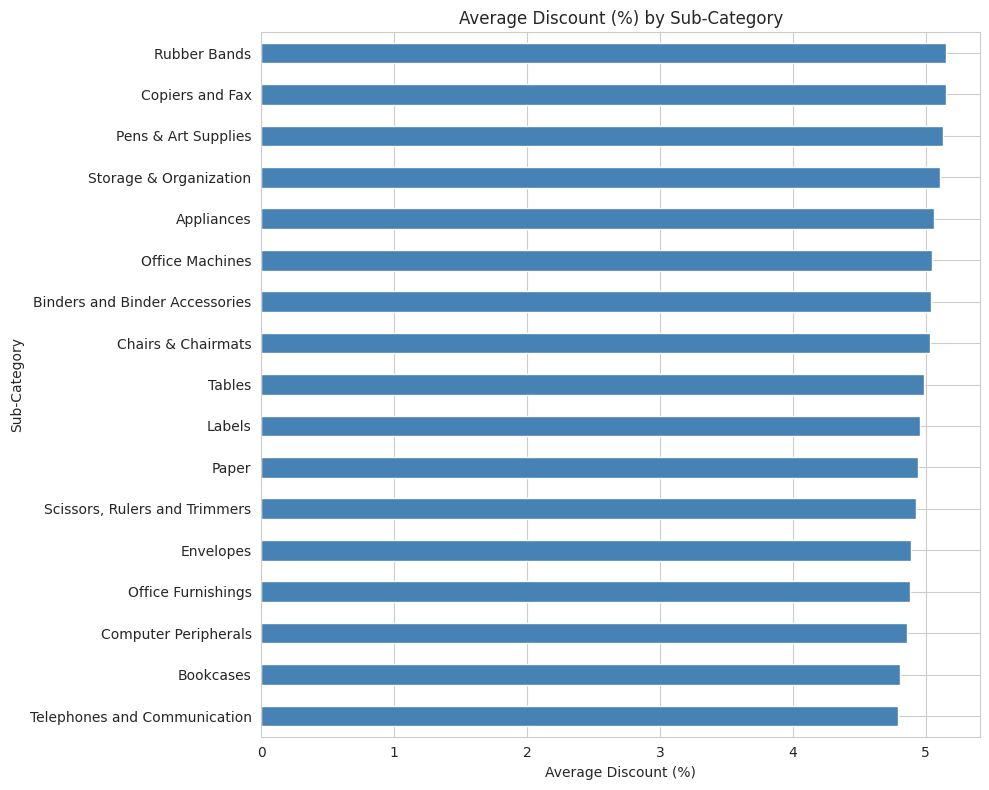

In [48]:
(subcat_discount * 100).sort_values().plot(kind="barh", color="steelblue", figsize=(10, 8))
plt.title("Average Discount (%) by Sub-Category")
plt.xlabel("Average Discount (%)")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.show()

**Insight:**
- Average discounts across all sub-categories are tightly clustered, ranging
  from **4.80%** (Telephones and Communication) to **5.15%** (Rubber Bands
  and Copiers and Fax) — a spread of just 0.35 percentage points.
- This is a meaningful finding on its own: there is **no sub-category being
  discounted dramatically more than others.** Discounting appears to be
  applied fairly evenly across the entire product range, rather than being
  concentrated in specific problem areas.
- This reinforces the Q25 finding: since discount levels are already nearly
  uniform across sub-categories, discounting cannot realistically explain
  why some sub-categories (like Tables or Bookcases, from Q14/Q18) are
  unprofitable while others aren't — everyone is being discounted at roughly
  the same rate, yet profitability outcomes vary widely. The cause of
  unprofitability lies elsewhere, likely in pricing or product cost
  structure, not discount policy.

### Q27. Are we discounting products that are already unprofitable?

In [49]:
discount_by_profitability = df.groupby("is_profitable")["discount"].mean()
print((discount_by_profitability * 100).round(2).astype(str) + "%")

is_profitable
False    5.19%
True     4.74%
Name: discount, dtype: object


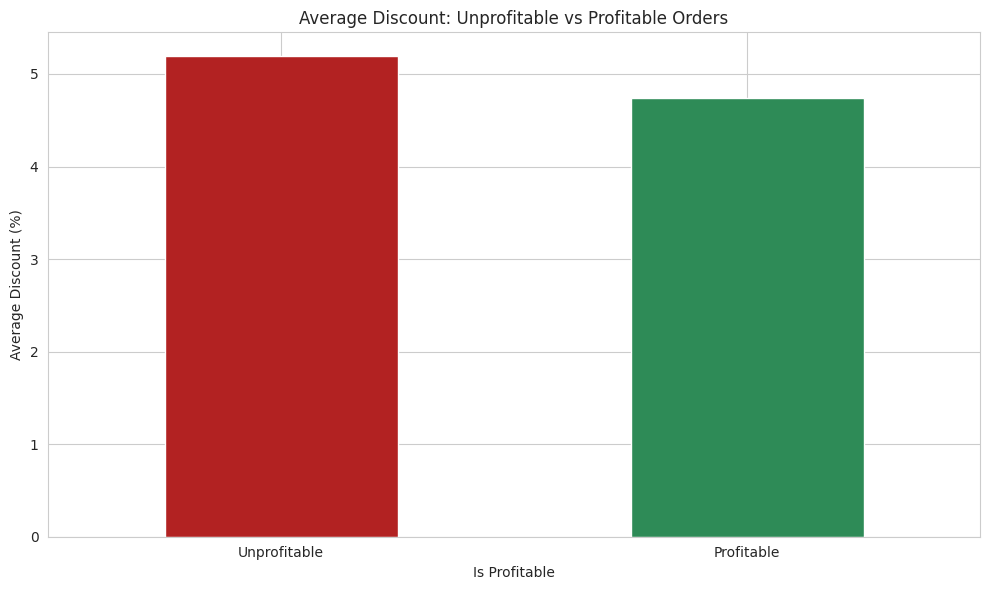

In [50]:
(discount_by_profitability * 100).plot(kind="bar", color=["firebrick", "seagreen"])
plt.title("Average Discount: Unprofitable vs Profitable Orders")
plt.xlabel("Is Profitable")
plt.ylabel("Average Discount (%)")
plt.xticks(ticks=[0, 1], labels=["Unprofitable", "Profitable"], rotation=0)
plt.tight_layout()
plt.show()

**Insight:**
- Unprofitable orders receive a **slightly higher** average discount
  (**5.19%**) than profitable orders (**4.74%**) — a difference of less
  than half a percentage point.
- This is a real but very small gap — not enough to call discounting a major
  driver of unprofitability, consistent with the near-zero correlations
  found in Q25. If discounting were a primary cause of losses, we'd expect a
  much larger gap between the two groups (e.g., 15% vs 5%, not 5.19% vs 4.74%).
- The honest answer: yes, technically, unprofitable orders are discounted
  slightly more on average — but the difference is too small to be the main
  explanation. This is a supporting data point, not new evidence, alongside
  Q25 and Q26 that discount policy is not the real driver of the business's
  profitability issues.

### Q28. What is the profit margin at different discount levels?

In [51]:
band_margin = df.groupby("discount_band").apply(
    lambda x: (x["profit"].sum() / x["sales"].sum()) * 100
)
print(band_margin.round(2).astype(str) + "%")

discount_band
No Discount      12.6%
Low             10.26%
Medium            6.5%
High           -49.76%
dtype: object


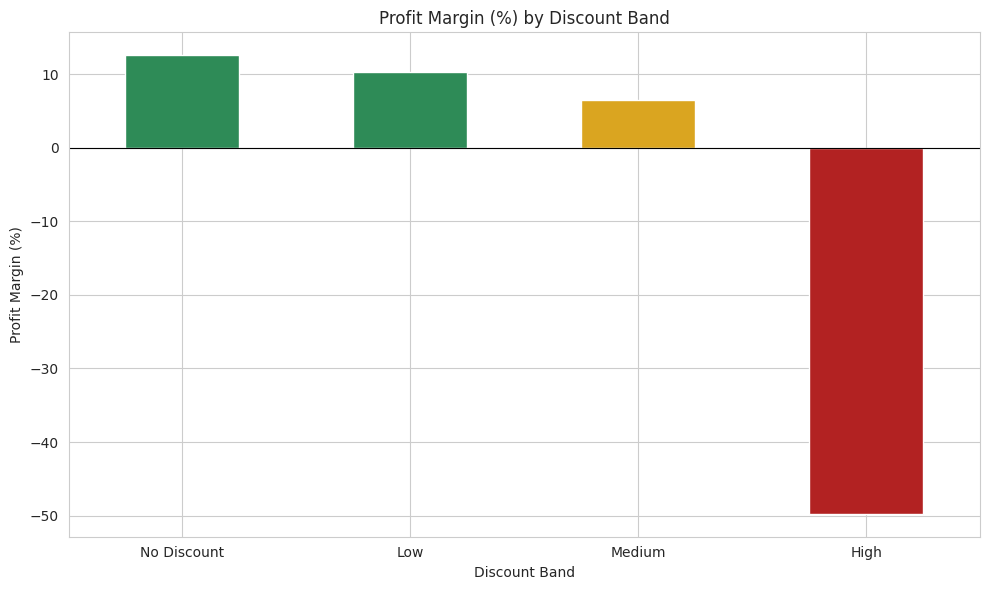

In [52]:
band_margin.plot(kind="bar", color=["seagreen", "seagreen", "goldenrod", "firebrick"])
plt.title("Profit Margin (%) by Discount Band")
plt.xlabel("Discount Band")
plt.ylabel("Profit Margin (%)")
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Insight:**
- There is a clear downward pattern: margin falls from **12.60%** (No
  Discount) to **10.26%** (Low) to **6.50%** (Medium), then collapses to
  **-49.76%** (High) — the business actually loses money overall on
  heavily-discounted orders.
- This appears to contradict Q25's near-zero correlation finding — but it
  doesn't, and the distinction matters: **correlation measures a straight-line
  relationship across individual orders**, while this margin calculation
  looks at **aggregated totals within each band**. A small number of extreme
  high-discount orders with severe losses (like Order #13088 from Notebook 3,
  at -1,144% margin) can dominate an aggregate sum without moving the overall
  correlation much, since correlation is influenced by the *pattern across
  all 8,399 individual rows*, not just the high-discount subset.
- **This is the most actionable finding in the Discount category so far**:
  the "High" discount band is where real financial damage concentrates.
  It's not that discounting *in general* hurts profit (Q25, Q26 confirmed
  it's applied fairly evenly and doesn't correlate broadly) — it's that a
  **specific tier of very deep discounts** appears to include severely
  underpriced or loss-making orders. Q29 (deepest discounts and their
  profit) will look at this directly at the order level.

### Q29. What are the orders with the deepest discounts, and what was their profit?

In [53]:
deepest_discounts = df.sort_values("discount", ascending=False)[
    ["order_id", "product_name", "discount", "sales", "profit"]
].head(10)

print(deepest_discounts.to_string(index=False))

 order_id                                                                   product_name  discount   sales  profit
     1154 Lesro Sheffield Collection Coffee Table, End Table, Center Table, Corner Table      0.25  663.78 -481.04
    26567                                            GE 4 Foot Flourescent Tube, 40 Watt      0.21  338.52  -17.75
    16133                                                   Tensor Computer Mounted Lamp      0.17   27.96   -9.13
    34853                                                       DAX Wood Document Frame.      0.16  651.90  -74.51
      229                                                        Nu-Dell Executive Frame      0.11  586.11   98.44
    21889                         Recycled Steel Personal File for Standard File Folders      0.10  817.18  103.38
    21894                                      Wirebound Service Call Books, 5 1/2" x 4"      0.10   54.30    1.27
    14406                                                                     Ac

**Insight:**
- The single deepest discount in the dataset is **25%**, on a Lesro Sheffield
  Collection furniture set — and it resulted in the largest loss in this list
  (**-\$481.04**) on \$663.78 in sales, a striking example of a heavy discount
  directly coinciding with a significant loss.
- Of these 10 deepest-discount orders, **6 are unprofitable** and only
  **4 are profitable** — a worse ratio than the business-wide average (where
  roughly 49% of orders are profitable, per Notebook 3). This suggests deep
  discounting genuinely does correlate with a *higher chance* of loss at the
  individual order level, even if it doesn't show up as a strong linear
  correlation across the whole dataset (Q25).
- Not every deep discount leads to a loss, though: the **Canon MP100DHII
  Printing Calculator** was discounted 10% and still generated **\$2,052.13**
  in profit on \$5,196.19 in sales — proof that discount level alone doesn't
  determine the outcome; the underlying product margin matters just as much.
- Taken together with Q28, this confirms the **High discount band specifically**
  (not moderate discounting in general) is where the real profitability risk
  concentrates — consistent with the -49.76% aggregate margin found there.

**Category 5 Summary:**

Discounting shows almost no linear relationship with profit across the full
dataset (Q25), and average discount rates are nearly uniform across all
sub-categories (Q26) and between profitable/unprofitable orders (Q27) —
discounting is not, on its own, a broad driver of unprofitability. However,
breaking margin down by discount band reveals a sharp cliff: orders in the
**High discount band** post a combined **-49.76% margin** (Q28), and the
individual deepest-discount orders examined in Q29 show a disproportionate
share of losses. The conclusion is nuanced: moderate discounting is not the
problem, but a specific tier of very deep discounts is strongly associated
with losses and merits a targeted pricing policy review.

## Category 6: Shipping & Operations

**Business Question:** "We want to understand our shipping performance and
whether it affects profitability."

This section examines shipping mode usage, delivery times, and their
relationship to profit and regional performance.

### Q30. Which shipping mode is used most frequently?

In [54]:
shipmode_counts = df["ship_mode"].value_counts()
print(shipmode_counts)

ship_mode
Regular Air       6270
Delivery Truck    1146
Express Air        983
Name: count, dtype: int64


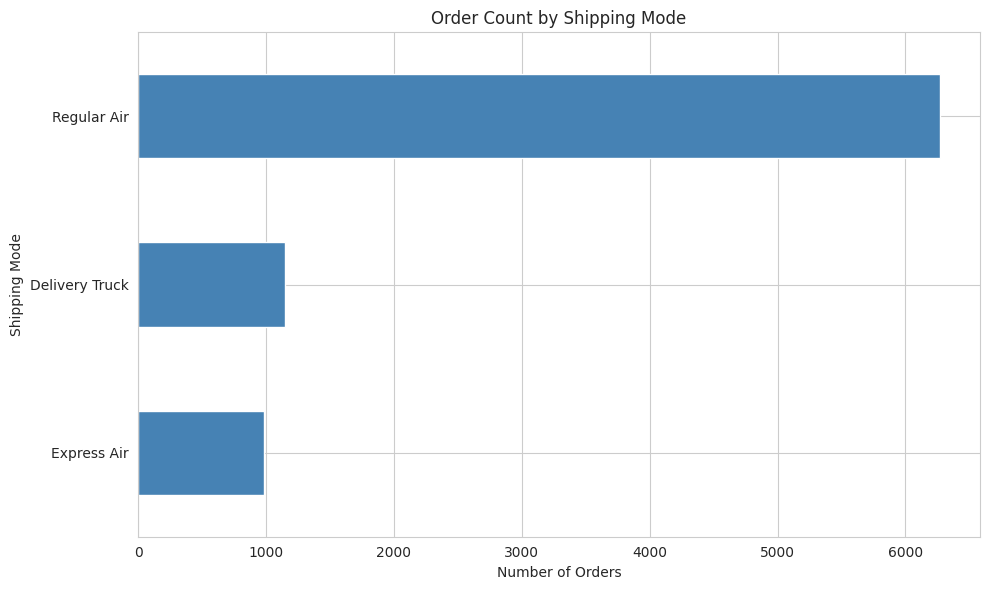

In [55]:
shipmode_counts.sort_values().plot(kind="barh", color="steelblue")
plt.title("Order Count by Shipping Mode")
plt.xlabel("Number of Orders")
plt.ylabel("Shipping Mode")
plt.tight_layout()
plt.show()

**Insight:**
- **Regular Air** is overwhelmingly the most-used shipping mode, accounting
  for **6,270 of 8,399 rows (about 75%)** — far ahead of Delivery Truck
  (1,146) and Express Air (983).
- This heavy reliance on a single shipping method means Regular Air's
  performance (cost, speed, associated profit) will dominate any
  company-wide shipping metric — worth keeping in mind for Q31-Q32, since
  Regular Air's numbers will likely resemble the overall average simply due
  to its scale, while Delivery Truck and Express Air represent smaller, more
  specialized use cases.

### Q31. What is the average shipping time per shipping mode?

In [56]:
shipping_time = df.groupby("ship_mode")["shipping_days"].mean().sort_values()
print(shipping_time.round(2))

ship_mode
Express Air      2.00
Regular Air      2.04
Delivery Truck   2.04
Name: shipping_days, dtype: float64


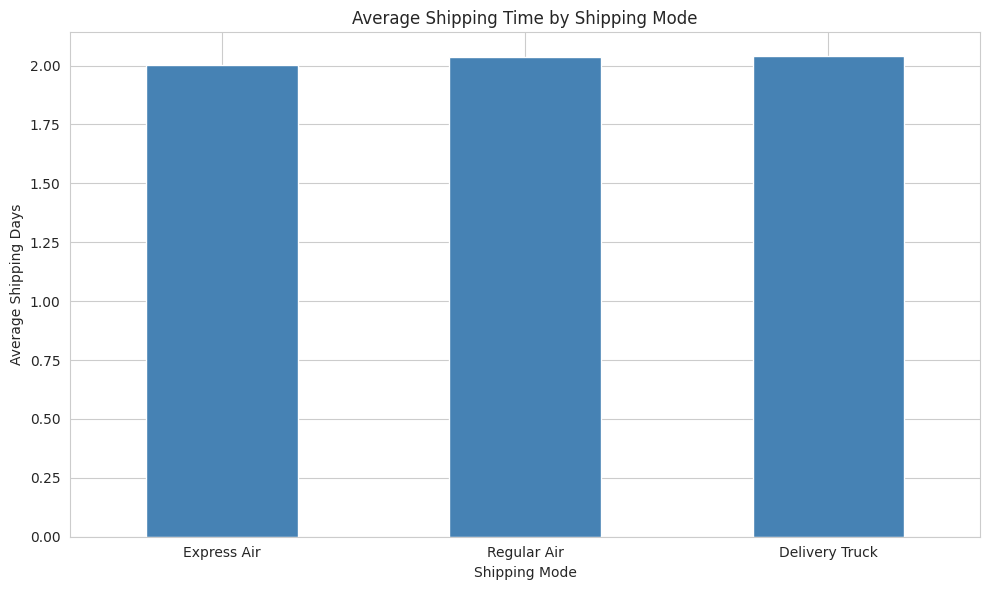

In [57]:
shipping_time.plot(kind="bar", color="steelblue")
plt.title("Average Shipping Time by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Average Shipping Days")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Insight:**
- All three shipping modes average almost exactly **2 days** — Express Air
  (2.00), Regular Air (2.04), and Delivery Truck (2.04) — a difference of
  only 0.04 days between the fastest and slowest.
- This is a notable finding: despite having different names suggesting
  different speeds (Express vs. Regular vs. Truck), **shipping mode has
  virtually no effect on actual delivery time** in this dataset. This aligns
  with the Notebook 3 finding that shipping_days had near-zero correlation
  with other variables, and that the one true outlier (Order #353's 92-day
  delay) was an isolated anomaly rather than a mode-driven pattern.
- Practical implication: if "Express Air" isn't meaningfully faster than
  "Regular Air" in practice, its likely-higher cost may not be delivering
  a real speed benefit — worth flagging as an operational question, though
  outside this notebook's scope to resolve.

### Q32. Which shipping mode is associated with the highest profit?

In [58]:
shipmode_profit = df.groupby("ship_mode")["profit"].sum().sort_values(ascending=False)
print(shipmode_profit.apply(fmt_currency))

ship_mode
Regular Air       $1,104,692.83
Delivery Truck      $269,644.84
Express Air         $147,430.29
Name: profit, dtype: object


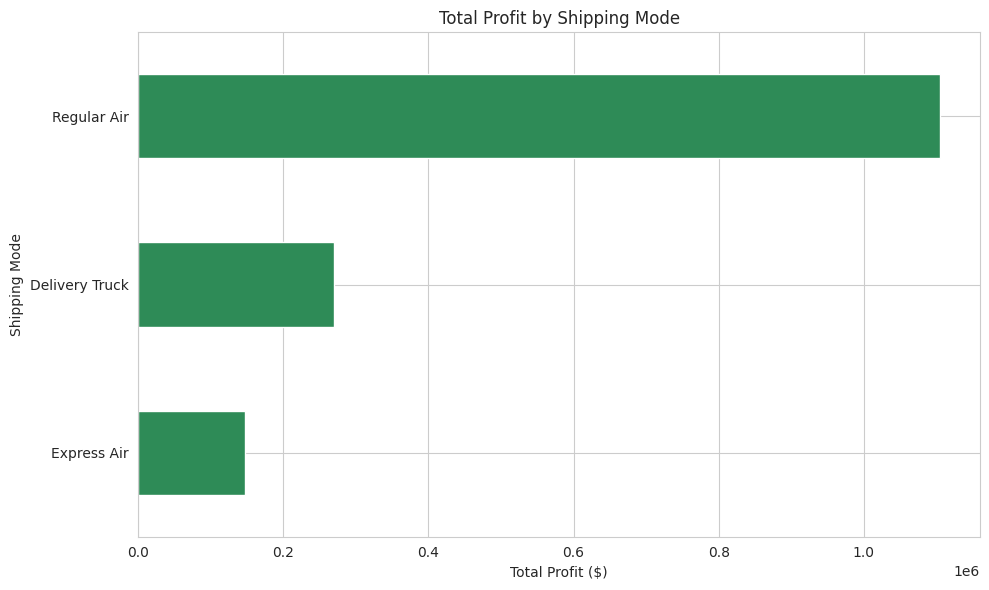

In [59]:
shipmode_profit.sort_values().plot(kind="barh", color="seagreen")
plt.title("Total Profit by Shipping Mode")
plt.xlabel("Total Profit ($)")
plt.ylabel("Shipping Mode")
plt.tight_layout()
plt.show()

**Insight:**
- **Regular Air** generates by far the most profit (**\$1.10M**), well ahead
  of Delivery Truck (**\$269,644.84**) and Express Air (**\$147,430.29**).
- This ranking directly mirrors Q30's order volume ranking — Regular Air
  handles roughly 75% of all orders, so its profit dominance is expected
  from scale rather than being a uniquely efficient shipping mode. Since Q31
  showed all three modes ship in essentially the same ~2 days, there's no
  clear operational reason favoring one mode's profitability over another;
  the difference here is simply a function of how many orders each mode
  carries.

### Q33. Which orders had unusually long shipping times?

In [61]:
shipping_threshold = df["shipping_days"].mean() + (3 * df["shipping_days"].std())

long_shipping = df[df["shipping_days"] > shipping_threshold][
    ["order_id", "product_name", "ship_mode", "shipping_days", "region"]
].sort_values("shipping_days", ascending=False)

print(f"Threshold (3 std above mean): {shipping_threshold:.2f} days")
print(f"Number of unusually long shipments: {len(long_shipping)}\n")
print(long_shipping.head(15).to_string(index=False))

Threshold (3 std above mean): 8.94 days
Number of unusually long shipments: 105

 order_id                                                                  product_name      ship_mode  shipping_days  region
      353                                           Quartet Alpha® White Chalk, 12/Pack    Regular Air             92    West
     1699                                                 #10 Self-Seal White Envelopes    Regular Air             84 Central
    19841                                                                           688    Regular Air             31    East
    19556                                                                           282    Regular Air             28    West
    19841                                             Staples SlimLine Pencil Sharpener    Regular Air             27    East
    23329                                                  Bell Sonecor JB700 Caller ID    Regular Air             24    West
    45408                            

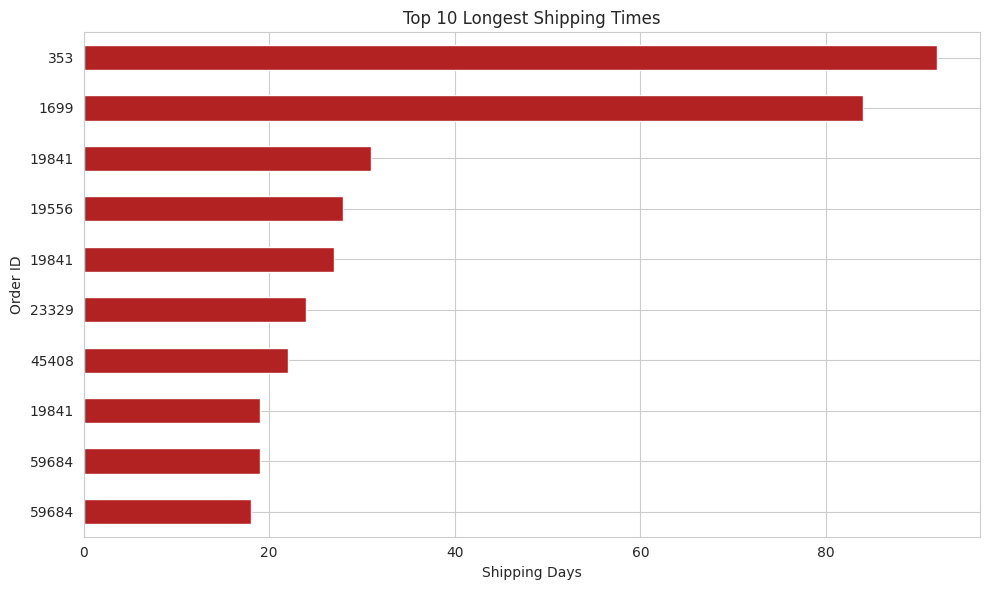

In [62]:
long_shipping.head(10).set_index("order_id")["shipping_days"].sort_values().plot(kind="barh", color="firebrick")
plt.title("Top 10 Longest Shipping Times")
plt.xlabel("Shipping Days")
plt.ylabel("Order ID")
plt.tight_layout()
plt.show()

**Insight:**
- Using a threshold of **8.94 days** (3 standard deviations above the mean),
  **105 orders** qualify as unusually long shipments out of 8,399 total rows
  — about **1.25%** of the dataset.
- **Order #353** (92 days) and **Order #1699** (84 days) are the two most
  extreme cases, both dramatically longer than the rest — close to each
  other in severity (roughly a 9.5% difference between them), confirming
  Order #353 is a genuine anomaly, though not entirely alone at that scale.
- After these top two, shipping times drop sharply: the next-longest cases
  (31, 28, 27, 24, 22 days) are still well above normal, but nowhere near as
  extreme, and the bulk of the 105 flagged orders cluster closer to the
  8.94-day threshold itself rather than near the top two outliers.
- **Regular Air** appears most frequently among the worst delays, but given
  it handles roughly 75% of all shipments (Q30), this is expected from
  volume alone rather than indicating Regular Air is disproportionately
  unreliable — the 105 flagged orders represent a small, genuine tail of
  delays rather than a systemic shipping problem across any one mode.

### Q34. Which region has the fastest average shipping time?

In [63]:
region_shipping = df.groupby("region")["shipping_days"].mean().sort_values()
print(region_shipping.round(2))

region
South     1.95
East      2.02
Central   2.06
West      2.09
Name: shipping_days, dtype: float64


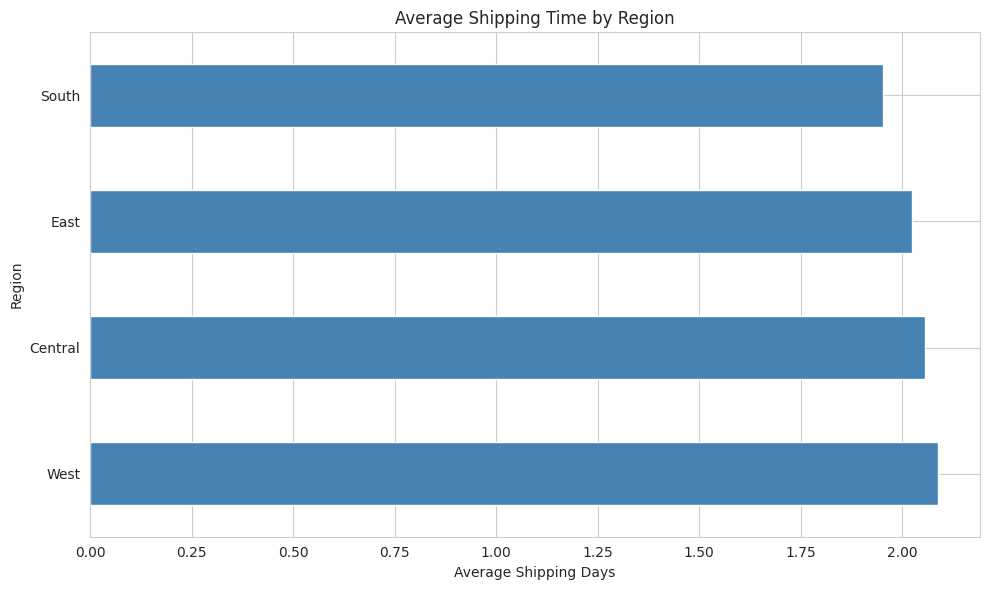

In [64]:
region_shipping.sort_values(ascending=False).plot(kind="barh", color="steelblue")
plt.title("Average Shipping Time by Region")
plt.xlabel("Average Shipping Days")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

**Insight:**
- **South** has the fastest average shipping time (**1.95 days**), while
  **West** is the slowest (**2.09 days**) — a gap of just 0.14 days,
  essentially negligible in practical terms.
- All four regions ship within roughly 2 days on average, reinforcing Q31's
  finding that shipping performance is highly consistent across the board —
  here at the regional level too, not just across shipping modes.
- Worth noting: **South** is also the region with the best profit margin
  (Q8, 13.41%) and **West** has the worst margin (Q8, 8.21%) — but the
  shipping time gap between them (0.14 days) is far too small to meaningfully
  explain that profitability difference. Shipping speed does not appear to
  be a driver of regional profit performance.

**Category 6 Summary:**

Shipping operations show strong consistency across the business: Regular Air
dominates by volume (75% of orders) and therefore leads in total profit by
scale, but all three shipping modes — and all four regions — deliver in
almost exactly the same ~2 days on average. A small tail of 105 orders
(about 1.25%) show unusually long shipping times, led by the extreme Order #353 and #1699 cases, but this represents a rare exception rather than a
systemic operational issue. Shipping performance does not appear to be a
meaningful driver of the profitability differences seen elsewhere in this
notebook.

## Category 7: Time Series & Trends

**Business Question:** "We want to understand seasonal patterns and
year-over-year growth to plan ahead."

This final section examines monthly, quarterly, and yearly patterns to
identify seasonality and measure the business's growth trajectory over time.

### Q35. Which month consistently has the highest sales across all years?

In [65]:
month_sales = df.groupby("month_name")["sales"].sum().sort_values(ascending=False)
print(month_sales.apply(fmt_currency))

month_name
December     $1,467,489.96
January      $1,444,923.38
October      $1,383,714.44
September    $1,337,956.96
March        $1,273,680.93
April        $1,216,483.44
February     $1,180,083.78
November     $1,163,393.37
May          $1,160,896.38
July         $1,141,104.35
August       $1,115,015.33
June         $1,030,858.51
Name: sales, dtype: object


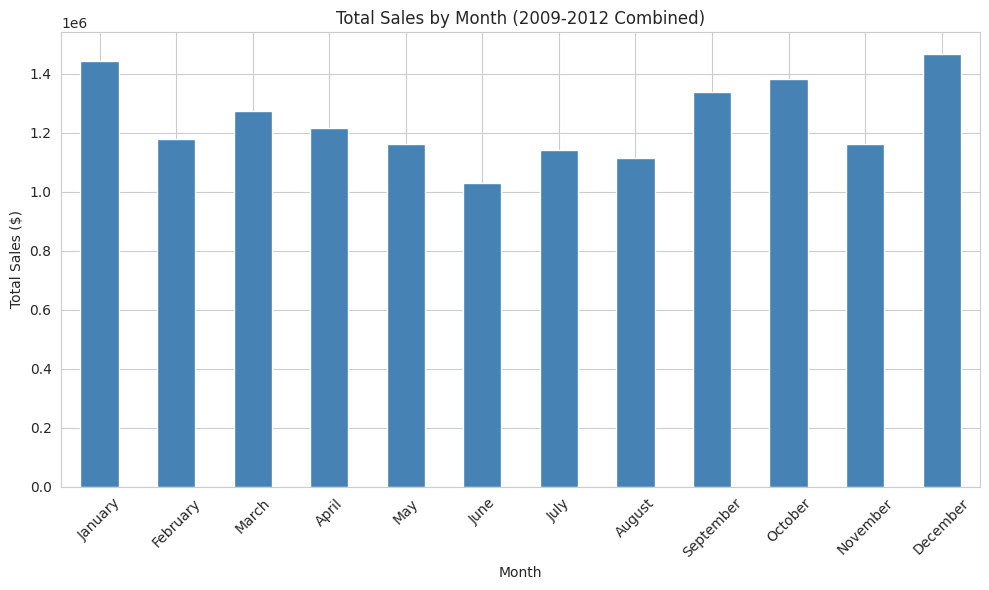

In [66]:
month_order = ["January", "February", "March", "April", "May", "June",
               "July", "August", "September", "October", "November", "December"]
month_sales.reindex(month_order).plot(kind="bar", color="steelblue")
plt.title("Total Sales by Month (2009-2012 Combined)")
plt.xlabel("Month")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Insight:**
- **December** has the highest combined sales across all four years
  (**\$1.47M**), closely followed by **January** (**\$1.44M**) — the two
  are nearly tied, and both bookend the calendar year.
- **June** is the lowest month (**\$1.03M**), roughly **30% below**
  December's peak — a meaningful seasonal dip in the middle of the year.
- The pattern suggests a **year-end/new-year sales peak** (December-January)
  and a **mid-year lull** (June-August), which is a useful signal for
  inventory planning and marketing timing, though Q37 will look more closely
  at whether this reflects a genuine recurring seasonal pattern or is driven
  by a specific year.

### Q36. Which quarter performs best in revenue and profit?

In [68]:
quarter_summary = df.groupby("quarter").agg(
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum")
)
print(quarter_summary.apply(lambda col: col.map(fmt_currency)))

           total_sales total_profit
quarter                            
Q1       $3,898,688.09  $378,749.23
Q2       $3,408,238.33  $358,238.80
Q3       $3,594,076.64  $359,903.47
Q4       $4,014,597.76  $424,876.46


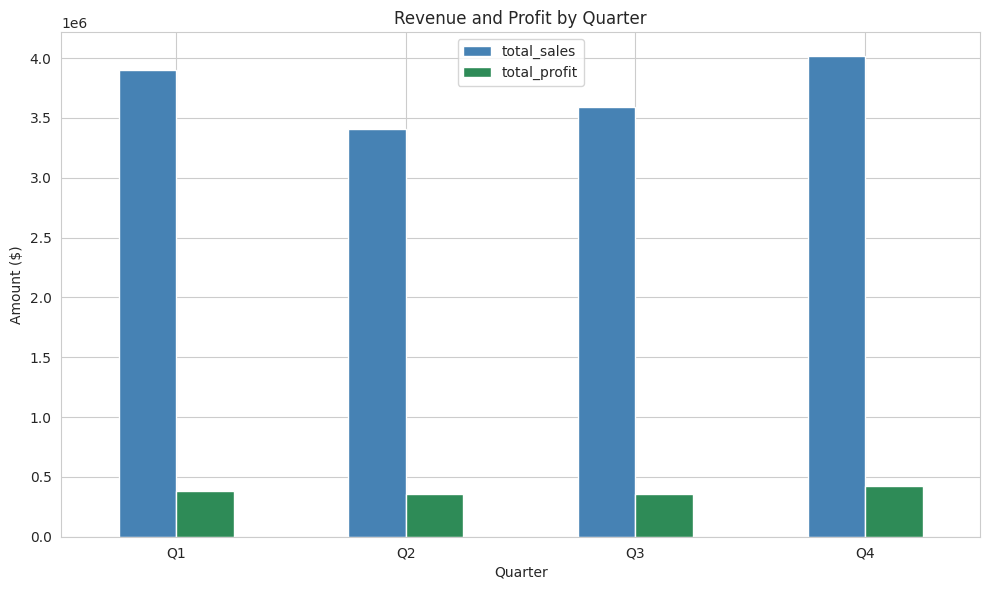

In [69]:
quarter_summary[["total_sales", "total_profit"]].plot(kind="bar", color=["steelblue", "seagreen"])
plt.title("Revenue and Profit by Quarter")
plt.xlabel("Quarter")
plt.ylabel("Amount ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Insight:**
- **Q4** performs best on both measures — highest revenue (**\$4.01M**) and
  highest profit (**\$424,876.46**) — consistent with Q35's finding that
  December (a Q4 month) is the single strongest sales month.
- **Q2** is the weakest quarter on both revenue (**\$3.41M**) and profit
  (**\$358,238.80**) — aligning with Q35's finding that June sits at the
  bottom of the monthly ranking.
- Profit doesn't scale perfectly with revenue across quarters: Q1 and Q3 have
  very different revenue (\$3.90M vs \$3.59M) but nearly identical profit
  (\$378,749 vs \$359,903) — another example of the revenue-profit
  disconnect seen throughout this notebook (regions, categories, products,
  customers).
- Overall, this confirms a genuine **year-end strength / mid-year softness**
  pattern at the quarterly level, matching what Q35 showed at the monthly
  level.

### Q37. Is there a seasonal pattern — do sales peak at certain times, consistently across years?

In [73]:
seasonal = df.groupby(["year", "month"])["sales"].sum().unstack(level='year')
print(seasonal.round(2))

year       2009      2010      2011      2012
month                                        
1     516302.96 336526.68 251467.23 340626.51
2     332480.64 271580.51 299890.14 276132.50
3     411628.73 217808.01 296035.87 348208.32
4     393276.48 266968.59 288213.40 268024.97
5     230145.54 283534.28 262628.50 384588.06
6     263456.07 293080.66 197740.85 276580.94
7     380503.97 229885.50 287905.19 242809.70
8     329754.72 207937.01 274578.48 302745.12
9     325292.31 418343.28 276049.80 318271.57
10    361555.27 365251.98 305660.45 351246.73
11    248933.43 290670.35 367769.50 256020.10
12    415809.35 368093.95 328877.31 354709.34


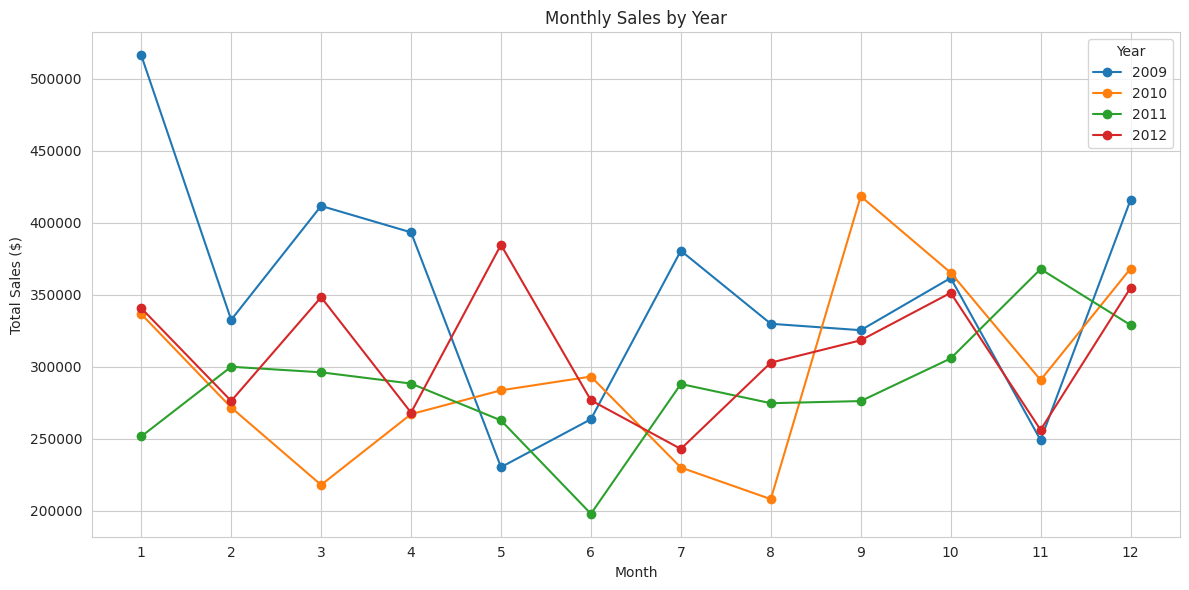

In [77]:
seasonal.plot(kind="line", marker="o", figsize=(12, 6))
plt.title("Monthly Sales by Year")
plt.xlabel("Month")
plt.ylabel("Total Sales ($)")
plt.xticks(ticks=range(1, 13))
plt.legend(title="Year")
plt.tight_layout()
plt.show()

**Insight:**
- There is **no single month that consistently peaks across all four years**
  — 2009 peaked in January (\$516,302.96), 2010 peaked in September
  (\$418,343.28), 2011 peaked in November (\$367,769.50), and 2012 peaked in
  May (\$384,588.06). The "top month" shifts every year.
- This means Q35's aggregated finding (December/January strongest, June
  weakest) is a **multi-year average pattern**, not something that reliably
  repeats in any individual year — 2009 in particular is doing a lot of the
  heavy lifting for that January result, given its unusually high start.
- The more honest conclusion: this business shows **month-to-month
  volatility rather than a dependable seasonal calendar**. Revenue swings
  significantly within every year, but the *timing* of the peaks and dips
  isn't consistent enough to say "always stock up before December" with
  confidence — it would need to be re-validated with more years of data
  before treating any single month as a reliable seasonal signal.

### Q38. Which month has the lowest sales?

In [78]:
lowest_month = df.groupby("month_name")["sales"].sum().sort_values().head(1)
print(lowest_month.apply(fmt_currency))

month_name
June    $1,030,858.51
Name: sales, dtype: object


**Insight:**
- **June** has the lowest total sales across all four years combined
  (**\$1,030,858.51**) — confirming the same finding already surfaced in
  Q35's ranked list and visible as a dip in Q37's year-by-year chart.
- However, Q37 also showed this isn't a rule that holds every single year —
  June wasn't the weakest month in every individual year, so this result
  should be read as the **overall multi-year pattern**, not a guarantee
  that June will always be the slowest month going forward.

### Q39. What is the year-over-year growth rate in revenue and profit?

In [79]:
yearly_summary = df.groupby("year").agg(
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum")
)
yearly_summary["sales_growth_%"] = yearly_summary["total_sales"].pct_change() * 100
yearly_summary["profit_growth_%"] = yearly_summary["total_profit"].pct_change() * 100

print(yearly_summary.round(2))

      total_sales  total_profit  sales_growth_%  profit_growth_%
year                                                            
2009   4209139.46     434538.79             NaN              NaN
2010   3549680.80     363871.38          -15.67           -16.26
2011   3436816.70     381455.99           -3.18             4.83
2012   3719963.86     341901.81            8.24           -10.37


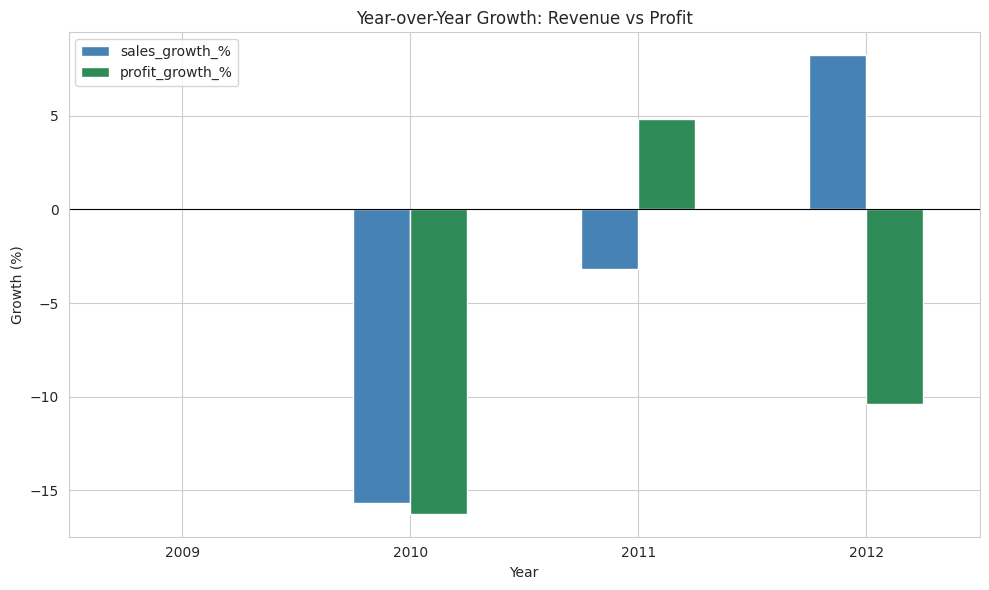

In [82]:
yearly_summary[["sales_growth_%", "profit_growth_%"]].plot(kind="bar", color=["steelblue", "seagreen"])
plt.title("Year-over-Year Growth: Revenue vs Profit")
plt.xlabel("Year")
plt.ylabel("Growth (%)")
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Insight:**
- The business had a **rough start**: 2010 saw a sharp decline in both
  revenue (**-15.67%**) and profit (**-16.26%**) compared to 2009 —
  consistent with 2009 being the peak year identified back in Q4.
- 2011 showed **mixed signals**: revenue kept falling slightly (**-3.18%**),
  but profit actually grew (**+4.83%**) — a sign of improved efficiency even
  as sales softened.
- 2012 reversed that pattern: revenue grew (**+8.24%**) but profit fell
  (**-10.37%**) — more sales did not translate into more profit, echoing the
  revenue-profit disconnect seen repeatedly throughout this notebook (across
  regions, categories, products, and customers).
- **No year has matched 2009's original strength** on either measure. Overall,
  the four-year growth story is **volatile and inconsistent rather than a
  clear trend** in either direction — revenue and profit don't move together
  from year to year, reinforcing that the business needs to actively manage
  margin, not just chase revenue growth, to return to 2009-level performance.

**Category 7 Summary:**

The business shows a genuine but modest seasonal pattern at the aggregate
level — December/January tend to be strongest, June tends to be weakest —
but this pattern is not reliable year by year, with each year peaking in a
different month. Year-over-year growth has been volatile: a strong 2009 was
followed by a sharp 2010 decline, and neither revenue nor profit has shown a
consistent trajectory since, with the two metrics frequently moving in
opposite directions. This reinforces the notebook's central theme: revenue
growth alone does not guarantee profit growth, and the business would
benefit from margin-focused strategies rather than pure sales-volume growth.

## Summary and Key Takeaways

This notebook answered all 39 business questions across seven categories,
translating the cleaned Superstore dataset into concrete business findings.

**Overall Performance:** The business generated \$14.92M in revenue and
\$1.52M in profit (10.20% margin) across 2009-2012, with a relatively flat
revenue trend and a declining profit trend since a strong 2009.

**Regional and Product Patterns:** Central leads in scale (revenue and
profit), while South and Small Business customers stand out for efficiency
(higher margins despite lower revenue). Technology is the strongest product
category; Furniture generates comparable revenue but converts almost none
of it into profit, driven primarily by Tables and Bookcases.

**Customers:** The business serves 795 unique customers. A small number of
high-revenue customers and products are quietly unprofitable — a recurring
pattern across nearly every category examined.

**Discounting:** Discounting is applied fairly uniformly and shows no strong
overall relationship with profit, but a specific High discount tier is
associated with severe, concentrated losses.

**Operations:** Shipping performance is highly consistent across modes and
regions, with a small number of extreme delays that appear to be isolated
anomalies rather than a systemic issue.

**Time Trends:** A mild seasonal pattern exists (year-end strength,
mid-year softness), but it is not reliable year to year, and overall growth
has been volatile rather than steadily positive.

**Central conclusion:** Across nearly every dimension examined — region,
category, product, customer, and time — revenue and profit do not move
together. The business's core opportunity is not generating more sales, but
improving margin discipline on the sales it already makes.

---

**Project:** Superstore Sales Analysis  
**Author:** Abdullah  
**Notebook:** 4 of 4 — Business Questions Analysis  
**Tools Used:** Python, Pandas, NumPy, Matplotlib, Seaborn  
**Environment:** Google Colab  

This notebook concludes a four-part end-to-end analysis: data understanding,
data cleaning, exploratory data analysis, and business question analysis.
All findings are derived directly from the cleaned dataset and are
reproducible from the notebooks in this project.

---